In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

Matplotlib is building the font cache; this may take a moment.


In [2]:
df = pd.read_csv("metro_daily_ridership.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
df

,date,line,ridership,trains_operated,rainfall_mm,holiday,special_event
0,2025-02-09,purple,49369.0,100,4.7,NaN,NaN
1,2025-05-02,Line 2 (Green),190039.0,159,1.0,NaN,NaN
2,2023-11-07,Line 1 (Blue),153967.0,146,5.8,NaN,NaN
3,2024-02-13,blue,162984.0,154,0.8,NaN,NaN
4,2023-07-15,Green,103890.0,128,3.6,NaN,NaN
...,...,...,...,...,...,...,...
2663,2024-07-16,blue,191301.0,166,11.4,NaN,NaN
2664,2023-10-06,blue line,159318.0,152,NaN,NaN,NaN
2665,2024-04-21,green,91245.0,139,4.9,NaN,NaN
2666,2024-05-29,green,146823.0,152,26.0,NaN,NaN


In [4]:
df.shape

(2668, 7)

In [5]:
df.head(30)

,date,line,ridership,trains_operated,rainfall_mm,holiday,special_event
0,2025-02-09,purple,49369.0,100,4.7,NaN,NaN
1,2025-05-02,Line 2 (Green),190039.0,159,1.0,NaN,NaN
2,2023-11-07,Line 1 (Blue),153967.0,146,5.8,NaN,NaN
3,2024-02-13,blue,162984.0,154,0.8,NaN,NaN
4,2023-07-15,Green,103890.0,128,3.6,NaN,NaN
5,2024-08-15,Purple,49606.0,108,7.4,Independence Day,NaN
6,2024-06-25,green,156479.0,152,0.2,NaN,NaN
7,2023-11-16,Green,123412.0,143,52.5,NaN,NaN
8,2024-06-22,purple,64696.0,90,1.4,NaN,NaN
9,2024-06-11,blue,NaN,162,0.2,NaN,NaN


In [6]:
df.tail(10)

,date,line,ridership,trains_operated,rainfall_mm,holiday,special_event
2658,2024-12-15,PURPLE LINE,49869.0,95,13.4,NaN,NaN
2659,2023-10-25,Line 1 (Blue),151624.0,149,5.8,NaN,NaN
2660,2024-08-27,purple,87557.0,100,0.9,NaN,NaN
2661,2023-09-23,GREEN LINE,96229.0,131,51.7,NaN,NaN
2662,2025-02-20,blue line,210283.0,167,0.3,NaN,NaN
2663,2024-07-16,blue,191301.0,166,11.4,NaN,NaN
2664,2023-10-06,blue line,159318.0,152,NaN,NaN,NaN
2665,2024-04-21,green,91245.0,139,4.9,NaN,NaN
2666,2024-05-29,green,146823.0,152,26.0,NaN,NaN
2667,2024-09-25,Line 1 (Blue),193207.0,168,3.6,NaN,NaN


In [7]:
df.columns

Index(['date', 'line', 'ridership', 'trains_operated', 'rainfall_mm',
       'holiday', 'special_event'],
      dtype='object')

In [8]:
df.dtypes

date                object
line                object
ridership          float64
trains_operated      int64
rainfall_mm        float64
holiday             object
special_event       object
dtype: object

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2668 entries, 0 to 2667
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   date             2668 non-null   object 
 1   line             2668 non-null   object 
 2   ridership        2628 non-null   float64
 3   trains_operated  2668 non-null   int64  
 4   rainfall_mm      2615 non-null   float64
 5   holiday          84 non-null     object 
 6   special_event    39 non-null     object 
dtypes: float64(2), int64(1), object(4)
memory usage: 146.0+ KB


In [10]:
df.describe()

,ridership,trains_operated,rainfall_mm
count,2628.000000,2668.000000,2615.000000
mean,127667.472603,138.994003,8.554034
std,46347.784696,23.145486,17.826596
min,0.000000,58.000000,0.000000
25%,93588.500000,132.000000,0.500000
50%,129324.500000,143.000000,1.900000
75%,160790.250000,155.000000,6.700000
max,377686.000000,179.000000,145.000000


In [11]:
print("Total Records:", df.shape[0])
print("Total Columns:", df.shape[1])

Total Records: 2668
Total Columns: 7


In [12]:
df.describe(include='all')

,date,line,ridership,trains_operated,rainfall_mm,holiday,special_event
count,2668,2668,2628.000000,2668.000000,2615.000000,84,39
unique,1093,15,NaN,NaN,NaN,15,6
top,2024-05-17,green,NaN,NaN,NaN,Labour Day,Cricket match
freq,4,204,NaN,NaN,NaN,8,11
mean,NaN,NaN,127667.472603,138.994003,8.554034,NaN,NaN
std,NaN,NaN,46347.784696,23.145486,17.826596,NaN,NaN
min,NaN,NaN,0.000000,58.000000,0.000000,NaN,NaN
25%,NaN,NaN,93588.500000,132.000000,0.500000,NaN,NaN
50%,NaN,NaN,129324.500000,143.000000,1.900000,NaN,NaN
75%,NaN,NaN,160790.250000,155.000000,6.700000,NaN,NaN


## Check missing values

In [13]:
df.isnull().sum()

date                  0
line                  0
ridership            40
trains_operated       0
rainfall_mm          53
holiday            2584
special_event      2629
dtype: int64

In [14]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_percentage

date                0.000000
line                0.000000
ridership           1.499250
trains_operated     0.000000
rainfall_mm         1.986507
holiday            96.851574
special_event      98.538231
dtype: float64

In [15]:
print("Total Duplicate Rows:", df.duplicated().sum())

Total Duplicate Rows: 32


In [16]:
df[df.duplicated()]

,date,line,ridership,trains_operated,rainfall_mm,holiday,special_event
182,2024-05-06,green,158304.0,155,3.3,NaN,NaN
337,2024-02-11,Line 1 (Blue),89541.0,149,0.3,NaN,NaN
710,2024-03-22,Green line,174324.0,148,0.2,NaN,NaN
757,2025-03-17,Line 2 (Green),173969.0,159,0.0,NaN,NaN
919,2023-08-25,Line 2 (Green),142317.0,137,0.1,NaN,NaN
1024,2022-11-29,BLUE,120489.0,143,53.5,NaN,NaN
1133,2023-11-27,Green line,120381.0,143,4.2,NaN,NaN
1158,2024-12-06,Purple,99581.0,101,2.2,NaN,NaN
1191,2022-12-05,GREEN LINE,114918.0,136,1.0,NaN,NaN
1376,2023-01-14,blue line,112041.0,134,1.9,NaN,NaN


In [17]:
print("Metro Lines:")
print(df['line'].unique())

print("\nHoliday Values:")
print(df['holiday'].unique())

print("\nSpecial Events:")
print(df['special_event'].unique())

Metro Lines:
['purple' 'Line 2 (Green)' 'Line 1 (Blue)' 'blue' 'Green' 'Purple'
 'green ' 'blue line' 'Blue' 'BLUE' 'green' 'PURPLE LINE' 'GREEN LINE'
 'Blue Line' 'Green line']

Holiday Values:
[nan 'Independence Day' 'Pongal' 'Ayudha Pooja' 'Diwali' 'Gandhi Jayanti'
 'Thiruvalluvar Day' 'Christmas' 'Bakrid' 'Bhogi' 'Labour Day'
 'Good Friday' 'Uzhavar Thirunal' 'Krishna Jayanthi' 'Republic Day'
 'Ganesh Chaturthi']

Special Events:
[nan 'Concert' 'Cricket match' 'Book fair' 'Expo' 'Marathon' 'IPL match']


In [18]:
print("Unique Dates:", df['date'].nunique())
print("Unique Metro Lines:", df['line'].nunique())
print("Unique Special Events:", df['special_event'].nunique())

Unique Dates: 1093
Unique Metro Lines: 15
Unique Special Events: 6


In [19]:
print("Zero Ridership:", (df['ridership'] == 0).sum())

print("Negative Ridership:", (df['ridership'] < 0).sum())

print("Negative Rainfall:", (df['rainfall_mm'] < 0).sum())

Zero Ridership: 6
Negative Ridership: 0
Negative Rainfall: 0


In [20]:
print("First Date:", df['date'].min())
print("Last Date:", df['date'].max())

First Date: 2022-07-01
Last Date: 2025-06-30


In [21]:
df['line'].value_counts()

line
green             204
blue line         195
Green             193
green             193
Line 1 (Blue)     186
GREEN LINE        183
blue              182
Blue Line         180
Blue              177
Green line        175
BLUE              174
Purple            170
purple            157
Line 2 (Green)    154
PURPLE LINE       145
Name: count, dtype: int64

In [22]:
df.groupby('line')['ridership'].agg(
    ['count', 'mean', 'min', 'max']
)

,count,mean,min,max
line,,,,
BLUE,171,148480.111111,37402.0,224894.0
Blue,176,150789.392045,51136.0,320570.0
Blue Line,176,143011.971591,0.0,225645.0
GREEN LINE,182,131773.027473,34603.0,287304.0
Green,189,130668.613757,52877.0,262652.0
Green line,171,130004.450292,34579.0,199793.0
Line 1 (Blue),184,150208.163043,0.0,221455.0
Line 2 (Green),153,126738.973856,0.0,200373.0
PURPLE LINE,143,73320.986014,6508.0,164616.0


In [23]:
duplicates = df[df.duplicated(keep=False)]

duplicates.sort_values(
    by=['date', 'line']
)

,date,line,ridership,trains_operated,rainfall_mm,holiday,special_event
517,2022-09-28,Blue Line,122211.0,137,50.5,NaN,NaN
1500,2022-09-28,Blue Line,122211.0,137,50.5,NaN,NaN
574,2022-11-29,BLUE,120489.0,143,53.5,NaN,NaN
1024,2022-11-29,BLUE,120489.0,143,53.5,NaN,NaN
1179,2022-12-05,GREEN LINE,114918.0,136,1.0,NaN,NaN
...,...,...,...,...,...,...,...
1789,2025-05-11,BLUE,104871.0,159,36.7,NaN,NaN
1327,2025-05-19,Green line,169471.0,157,4.9,NaN,NaN
2527,2025-05-19,Green line,169471.0,157,4.9,NaN,NaN
1715,2025-06-12,blue line,223531.0,174,0.7,NaN,NaN


In [24]:
df.duplicated(subset=['date', 'line']).sum()

32

## Data cleaning and preprocessing

In [25]:
df_clean = df.copy()

print("Original Dataset Shape:", df.shape)
print("Working Dataset Shape:", df_clean.shape)

Original Dataset Shape: (2668, 7)
Working Dataset Shape: (2668, 7)


In [26]:
#Convert Date into Datetime

df_clean['date'] = pd.to_datetime(df_clean['date'])

print(df_clean['date'].dtype)

datetime64[ns]


In [27]:
#Standardizing metro line names
line_mapping = {
    'blue': 'Blue',
    'blue line': 'Blue',
    'line 1 (blue)': 'Blue',

    'green': 'Green',
    'green line': 'Green',
    'line 2 (green)': 'Green',

    'purple': 'Purple',
    'purple line': 'Purple'
}

In [28]:
df_clean['line'] = (
    df_clean['line']
    .str.strip()
    .str.lower()
    .map(line_mapping)
)

In [29]:
print("Unique Metro Lines:")
print(df_clean['line'].unique())

print("\nNumber of Unique Lines:")
print(df_clean['line'].nunique())

Unique Metro Lines:
['Purple' 'Green' 'Blue']

Number of Unique Lines:
3


In [30]:
#Standardize Special Event Labels
df_clean['special_event'] = (
    df_clean['special_event']
    .replace({
        'IPL match': 'Cricket match'
    })
)

In [31]:
df_clean['special_event'].value_counts(dropna=False)

special_event
NaN              2629
Cricket match      15
Book fair           7
Marathon            7
Concert             5
Expo                5
Name: count, dtype: int64

In [32]:
print("Dataset Shape:", df_clean.shape)

print("\nMetro Lines:")
print(df_clean['line'].value_counts())

print("\nSpecial Events:")
print(df_clean['special_event'].value_counts(dropna=False))

print("\nDate Data Type:")
print(df_clean['date'].dtype)

Dataset Shape: (2668, 7)

Metro Lines:
line
Green     1102
Blue      1094
Purple     472
Name: count, dtype: int64

Special Events:
special_event
NaN              2629
Cricket match      15
Book fair           7
Marathon            7
Concert             5
Expo                5
Name: count, dtype: int64

Date Data Type:
datetime64[ns]


In [33]:
 print("Duplicate Records:", df_clean.duplicated().sum())

Duplicate Records: 32


In [34]:
df_clean = df_clean.drop_duplicates()

In [35]:
print("Dataset Shape After Removing Duplicates:", df_clean.shape)

print("Remaining Duplicate Rows:", df_clean.duplicated().sum())

Dataset Shape After Removing Duplicates: (2636, 7)
Remaining Duplicate Rows: 0


In [36]:
duplicate_keys = df_clean.duplicated(
    subset=['date', 'line']
).sum()

print("Duplicate Date-Line Combinations:", duplicate_keys)

Duplicate Date-Line Combinations: 0


In [37]:
zero_ridership = df_clean[df_clean['ridership'] == 0]

zero_ridership

,date,line,ridership,trains_operated,rainfall_mm,holiday,special_event
141,2023-07-12,Green,0.0,142,0.6,NaN,NaN
166,2025-06-22,Blue,0.0,160,5.9,NaN,NaN
455,2023-11-17,Green,0.0,142,11.0,NaN,NaN
566,2025-04-21,Purple,0.0,107,1.2,NaN,NaN
808,2023-10-22,Blue,0.0,142,NaN,NaN,NaN
2111,2022-12-04,Blue,0.0,137,5.7,NaN,NaN


In [38]:
print("Missing Ridership:", df_clean['ridership'].isnull().sum())

Missing Ridership: 40


In [39]:
zero_ridership = df_clean[df_clean['ridership'] == 0]

zero_ridership

,date,line,ridership,trains_operated,rainfall_mm,holiday,special_event
141,2023-07-12,Green,0.0,142,0.6,NaN,NaN
166,2025-06-22,Blue,0.0,160,5.9,NaN,NaN
455,2023-11-17,Green,0.0,142,11.0,NaN,NaN
566,2025-04-21,Purple,0.0,107,1.2,NaN,NaN
808,2023-10-22,Blue,0.0,142,NaN,NaN,NaN
2111,2022-12-04,Blue,0.0,137,5.7,NaN,NaN


In [40]:
df_clean.loc[df_clean['ridership'] == 0, 'ridership'] = np.nan

print("Zero Ridership Remaining:",
      (df_clean['ridership'] == 0).sum())

print("Missing Ridership:",
      df_clean['ridership'].isnull().sum())

Zero Ridership Remaining: 0
Missing Ridership: 46


In [41]:
df_clean = df_clean.sort_values(
    by=['line', 'date']
).reset_index(drop=True)

In [42]:
df_clean['weekday'] = df_clean['date'].dt.dayofweek

In [43]:
df_clean['weekday_median'] = (
    df_clean.groupby(['line', 'weekday'])['ridership']
    .transform(
        lambda x: x.rolling(
            window=5,
            center=True,
            min_periods=3
        ).median()
    )
)

In [44]:
df_clean['ridership_ratio'] = (
    df_clean['ridership'] / df_clean['weekday_median']
)

In [45]:
high_outliers = df_clean[
    df_clean['ridership_ratio'] > 1.7
]

high_outliers[
    ['date', 'line', 'ridership',
     'weekday_median', 'ridership_ratio']
]

,date,line,ridership,weekday_median,ridership_ratio
232,2023-02-20,Blue,281410.0,137346.0,2.048913
236,2023-02-24,Blue,314394.0,156210.0,2.012637
756,2024-08-05,Blue,320570.0,179770.0,1.783223
1159,2022-09-18,Green,122752.0,62326.0,1.969515
1524,2023-09-19,Green,262652.0,128670.0,2.041284
1689,2024-03-05,Green,292364.0,158314.0,1.846735
1690,2024-03-06,Green,287304.0,160797.0,1.786750
2163,2025-06-27,Green,377686.0,194830.0,1.938541
2386,2024-10-21,Purple,164616.0,85394.0,1.927723


In [46]:
outlier_indices = high_outliers.index

df_clean.loc[outlier_indices, 'ridership'] = np.nan

In [47]:
print("Total Missing Ridership:",
      df_clean['ridership'].isnull().sum())

Total Missing Ridership: 55


In [48]:
print("Current Dataset Shape:", df_clean.shape)

print("\nRecords Per Line:")
print(df_clean['line'].value_counts())

Current Dataset Shape: (2636, 10)

Records Per Line:
line
Green     1085
Blue      1081
Purple     470
Name: count, dtype: int64


In [49]:
df_clean = df_clean.drop(
    columns=['weekday', 'weekday_median', 'ridership_ratio'],
    errors='ignore'
)

line_start_dates = {
    'Blue': '2022-07-01',
    'Green': '2022-07-01',
    'Purple': '2024-03-11'
}

end_date = df_clean['date'].max()

complete_data = []

for line, start_date in line_start_dates.items():

    dates = pd.date_range(
        start=start_date,
        end=end_date,
        freq='D'
    )

    line_data = (
        df_clean[df_clean['line'] == line]
        .set_index('date')
        .reindex(dates)
    )

    line_data['line'] = line
    line_data.index.name = 'date'

    complete_data.append(line_data.reset_index())

df_clean = pd.concat(
    complete_data,
    ignore_index=True
)

df_clean = df_clean.sort_values(
    ['date', 'line']
).reset_index(drop=True)

In [50]:
print("Updated Dataset Shape:", df_clean.shape)

print("\nRecords Per Line:")
print(df_clean['line'].value_counts())

Updated Dataset Shape: (2669, 7)

Records Per Line:
line
Blue      1096
Green     1096
Purple     477
Name: count, dtype: int64


In [51]:
df_clean.isnull().sum()

date                  0
line                  0
ridership            88
trains_operated      33
rainfall_mm          86
holiday            2586
special_event      2630
dtype: int64

In [52]:
df_clean['weekday'] = df_clean['date'].dt.dayofweek

In [53]:
for line in df_clean['line'].unique():

    mask = df_clean['line'] == line

    line_data = df_clean.loc[mask].copy()

    for idx in line_data[line_data['ridership'].isnull()].index:

        target_date = df_clean.loc[idx, 'date']
        target_weekday = target_date.dayofweek

        nearby_values = line_data[
            (line_data['weekday'] == target_weekday) &
            (line_data['date'] != target_date) &
            (line_data['ridership'].notna()) &
            ((line_data['date'] - target_date).abs().dt.days <= 14)
        ]['ridership']

        if not nearby_values.empty:
            df_clean.loc[idx, 'ridership'] = nearby_values.median()

In [54]:
df_clean['ridership'].isnull().sum()

0

In [55]:
df_clean['rainfall_mm'] = (
    df_clean.groupby('date')['rainfall_mm']
    .transform(lambda x: x.fillna(x.median()))
)

In [56]:
df_clean['rainfall_mm'] = df_clean['rainfall_mm'].fillna(
    df_clean['rainfall_mm'].median()
)

In [57]:
df_clean['holiday'] = df_clean['holiday'].fillna('No Holiday')

df_clean['special_event'] = df_clean['special_event'].fillna('No Event')

In [58]:
df_clean['trains_operated'].isnull().sum()

33

In [59]:
df_clean['trains_operated'] = (
    df_clean.groupby(['line', 'weekday'])['trains_operated']
    .transform(lambda x: x.fillna(x.median()))
)

In [60]:
print("Missing Values After Cleaning:")
print(df_clean.isnull().sum())

Missing Values After Cleaning:
date               0
line               0
ridership          0
trains_operated    0
rainfall_mm        0
holiday            0
special_event      0
weekday            0
dtype: int64


In [61]:
df_clean.drop(columns=['weekday'], inplace=True)

In [62]:
print("Final Dataset Shape:", df_clean.shape)

print("\nRecords Per Line:")
print(df_clean['line'].value_counts())

print("\nDuplicate Records:", df_clean.duplicated().sum())

print("\nMissing Values:", df_clean.isnull().sum().sum())

print("\nDate Range:")
print(df_clean['date'].min(), "to", df_clean['date'].max())

Final Dataset Shape: (2669, 7)

Records Per Line:
line
Blue      1096
Green     1096
Purple     477
Name: count, dtype: int64

Duplicate Records: 0

Missing Values: 0

Date Range:
2022-07-01 00:00:00 to 2025-06-30 00:00:00


## Exploratory Data Analysis (EDA)

In [63]:
daily_ridership = (
    df_clean.groupby('date')['ridership']
    .sum()
    .reset_index()
)

daily_ridership.head()

,date,ridership
0,2022-07-01,271997.0
1,2022-07-02,194651.0
2,2022-07-03,136011.0
3,2022-07-04,236543.0
4,2022-07-05,239257.0


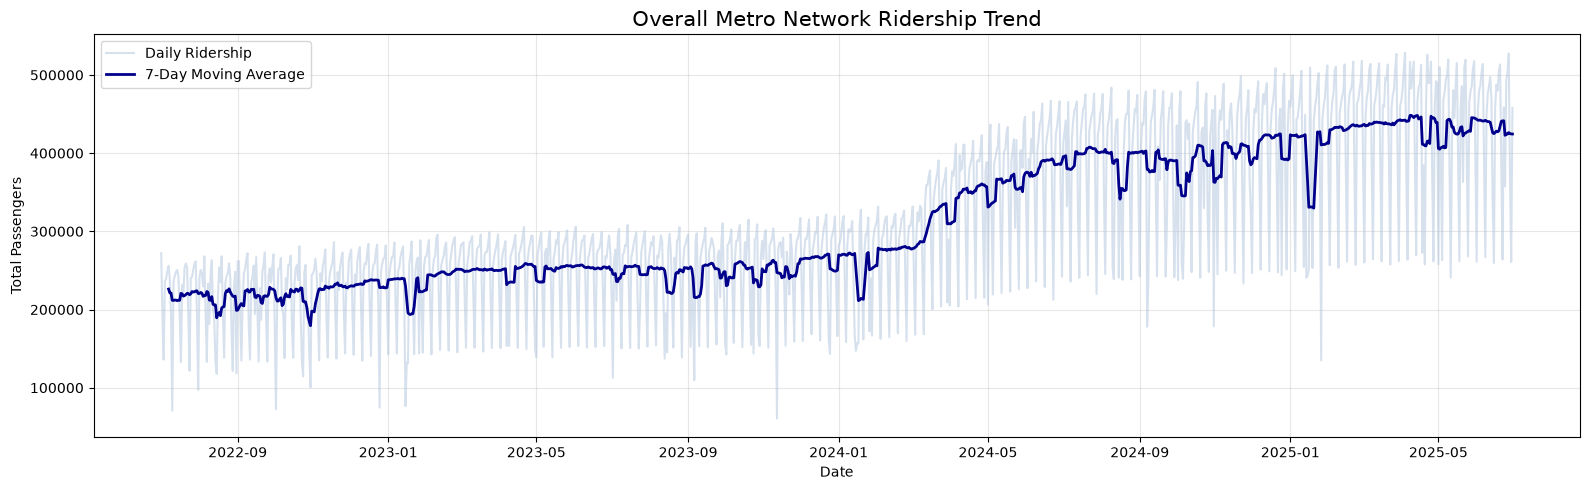

In [64]:
plt.figure(figsize=(16, 5))

plt.plot(
    daily_ridership['date'],
    daily_ridership['ridership'],
    color='lightsteelblue',
    alpha=0.5,
    label='Daily Ridership'
)

plt.plot(
    daily_ridership['date'],
    daily_ridership['ridership'].rolling(7).mean(),
    color='darkblue',
    linewidth=2,
    label='7-Day Moving Average'
)

plt.title('Overall Metro Network Ridership Trend', fontsize=15)
plt.xlabel('Date')
plt.ylabel('Total Passengers')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [65]:
monthly_ridership = (
    df_clean.groupby([
        pd.Grouper(key='date', freq='MS'),
        'line'
    ])['ridership']
    .sum()
    .reset_index()
)

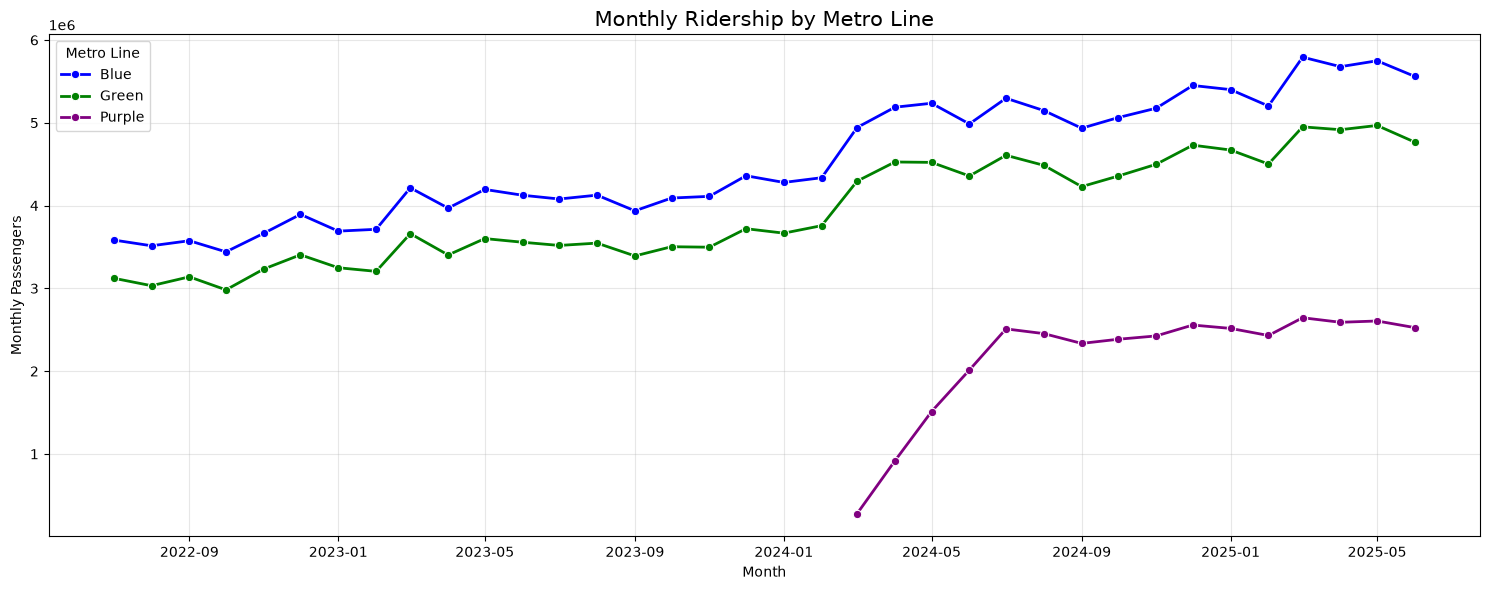

In [66]:
line_colors = {
    'Blue': 'blue',
    'Green': 'green',
    'Purple': 'purple'
}

plt.figure(figsize=(15, 6))

sns.lineplot(
    data=monthly_ridership,
    x='date',
    y='ridership',
    hue='line',
    hue_order=['Blue', 'Green', 'Purple'],
    palette=line_colors,
    marker='o',
    linewidth=2
)

plt.title('Monthly Ridership by Metro Line', fontsize=15)
plt.xlabel('Month')
plt.ylabel('Monthly Passengers')
plt.legend(title='Metro Line')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

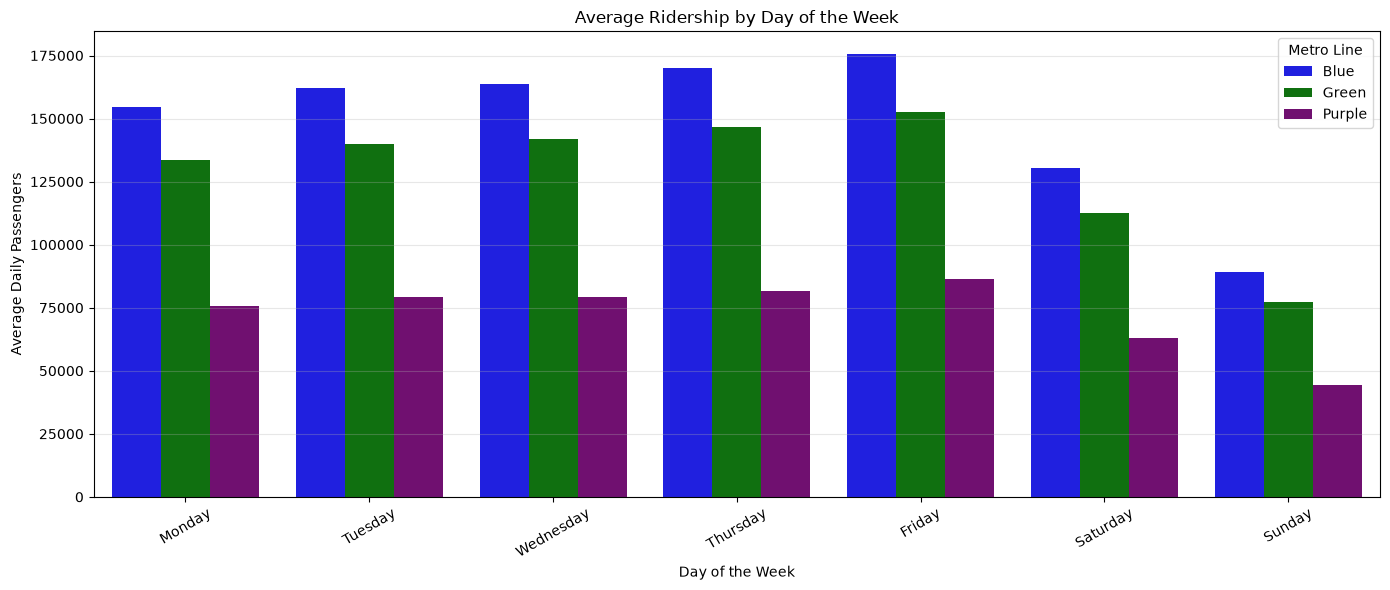

In [67]:
df_clean['day_name'] = df_clean['date'].dt.day_name()

weekday_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

weekday_ridership = (
    df_clean.groupby(['line', 'day_name'])['ridership']
    .mean()
    .reset_index()
)

plt.figure(figsize=(14, 6))

sns.barplot(
    data=weekday_ridership,
    x='day_name',
    y='ridership',
    hue='line',
    order=weekday_order,
    hue_order=['Blue', 'Green', 'Purple'],
    palette=line_colors
)

plt.title('Average Ridership by Day of the Week')
plt.xlabel('Day of the Week')
plt.ylabel('Average Daily Passengers')
plt.xticks(rotation=30)
plt.legend(title='Metro Line')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

## Rainfall vs Ridership Analysis

In [68]:
rain_ridership = (
    df_clean.groupby('date')
    .agg(
        network_ridership=('ridership', 'sum'),
        rainfall_mm=('rainfall_mm', 'first')
    )
    .reset_index()
)

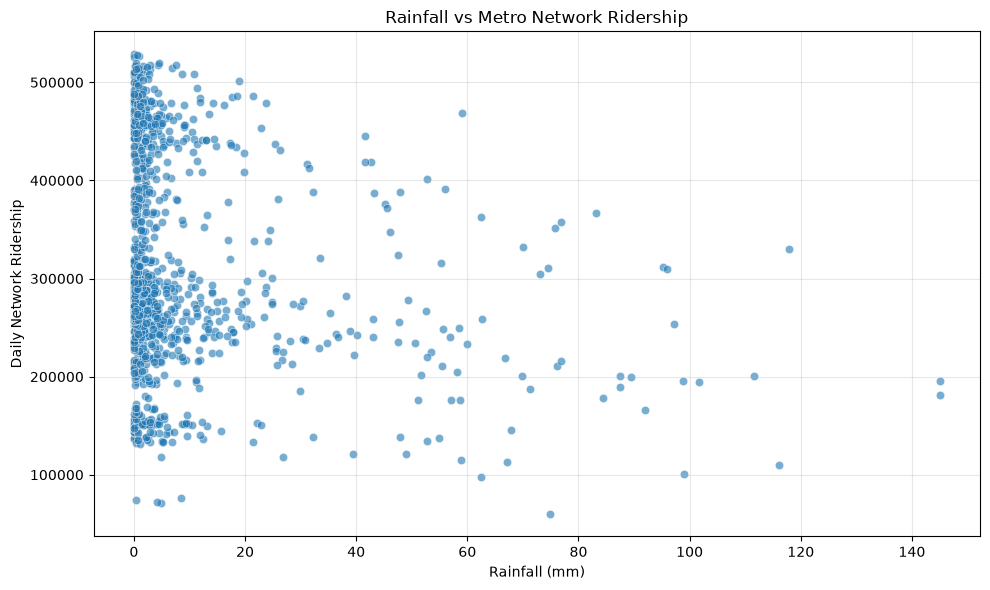

In [69]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=rain_ridership,
    x='rainfall_mm',
    y='network_ridership',
    alpha=0.6
)

plt.title('Rainfall vs Metro Network Ridership')
plt.xlabel('Rainfall (mm)')
plt.ylabel('Daily Network Ridership')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [70]:
rain_correlation = rain_ridership[
    ['rainfall_mm', 'network_ridership']
].corr().iloc[0, 1]

print(f"Rainfall-Ridership Correlation: {rain_correlation:.3f}")

Rainfall-Ridership Correlation: -0.188


## Holiday and Special Event Impact Analysis

In [71]:
holiday_event = (
    df_clean.groupby('date')
    .agg(
        network_ridership=('ridership', 'sum'),
        holiday=('holiday', 'first'),
        special_event=('special_event', 'first')
    )
    .reset_index()
)

holiday_event['day_type'] = np.where(
    holiday_event['holiday'] == 'No Holiday',
    'Normal Day',
    'Holiday'
)

holiday_event['event_type'] = np.where(
    holiday_event['special_event'] == 'No Event',
    'No Event',
    'Special Event'
)

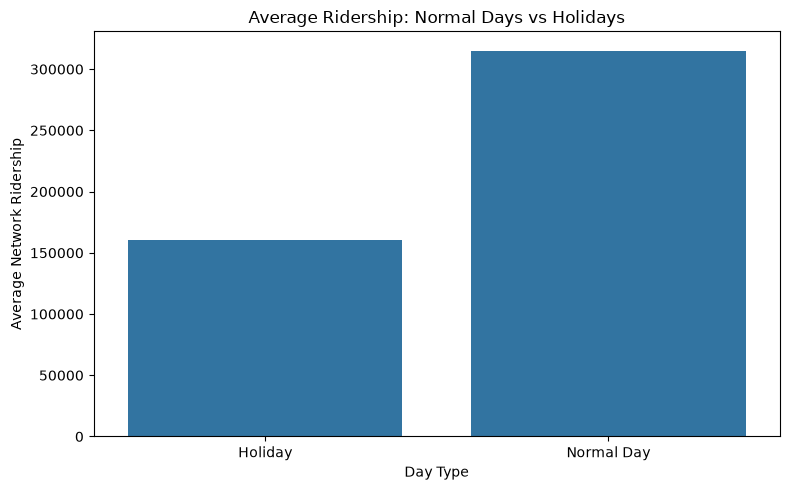

     day_type  network_ridership
0     Holiday      160534.485714
1  Normal Day      315115.591423


In [72]:
holiday_avg = (
    holiday_event.groupby('day_type')['network_ridership']
    .mean()
    .reset_index()
)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=holiday_avg,
    x='day_type',
    y='network_ridership'
)

plt.title('Average Ridership: Normal Days vs Holidays')
plt.xlabel('Day Type')
plt.ylabel('Average Network Ridership')
plt.tight_layout()
plt.show()

print(holiday_avg)

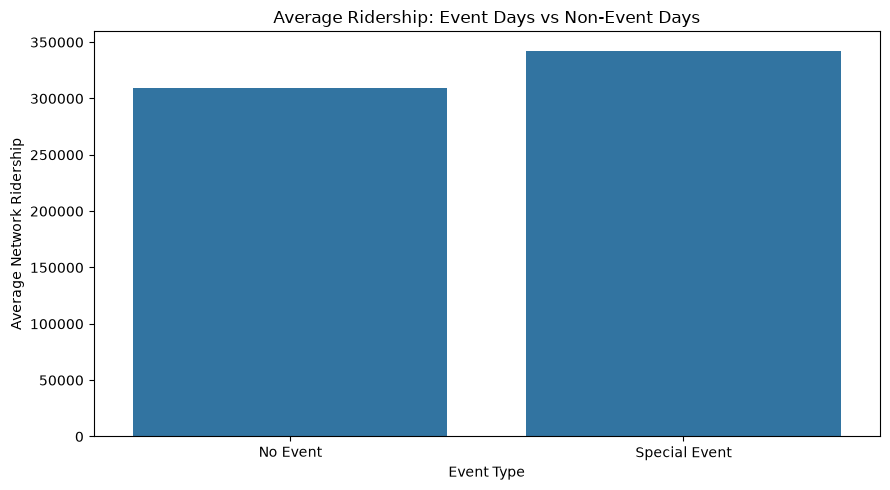

      event_type  network_ridership
0       No Event      309700.618056
1  Special Event      342480.125000


In [73]:
event_avg = (
    holiday_event.groupby('event_type')['network_ridership']
    .mean()
    .reset_index()
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=event_avg,
    x='event_type',
    y='network_ridership'
)

plt.title('Average Ridership: Event Days vs Non-Event Days')
plt.xlabel('Event Type')
plt.ylabel('Average Network Ridership')
plt.tight_layout()
plt.show()

print(event_avg)

<Figure size 1400x500 with 0 Axes>

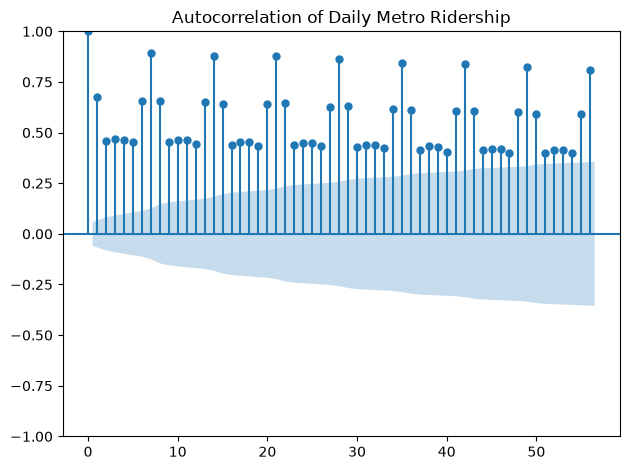

In [74]:
from statsmodels.graphics.tsaplots import plot_acf

network_series = (
    df_clean.groupby('date')['ridership']
    .sum()
    .sort_index()
)

plt.figure(figsize=(14, 5))

plot_acf(
    network_series,
    lags=56,
    title='Autocorrelation of Daily Metro Ridership'
)

plt.tight_layout()
plt.show()

## Feature Engineering

In [75]:
df_model = df_clean.copy()

df_model['day_of_week'] = df_model['date'].dt.dayofweek
df_model['day'] = df_model['date'].dt.day
df_model['month'] = df_model['date'].dt.month
df_model['quarter'] = df_model['date'].dt.quarter
df_model['year'] = df_model['date'].dt.year
df_model['week_of_year'] = df_model['date'].dt.isocalendar().week.astype(int)

df_model['is_weekend'] = (
    df_model['day_of_week'].isin([5, 6]).astype(int)
)

In [76]:
df_model['is_holiday'] = (
    df_model['holiday'] != 'No Holiday'
).astype(int)

df_model['is_special_event'] = (
    df_model['special_event'] != 'No Event'
).astype(int)

In [77]:
df_model['is_day_after_holiday'] = (
    df_model.groupby('line')['is_holiday']
    .shift(1)
    .fillna(0)
    .astype(int)
)

In [78]:
line_opening_dates = {
    'Blue': pd.Timestamp('2015-01-01'),
    'Green': pd.Timestamp('2015-01-01'),
    'Purple': pd.Timestamp('2024-03-11')
}

df_model['line_open_date'] = df_model['line'].map(
    line_opening_dates
)

df_model['days_since_open'] = (
    df_model['date'] - df_model['line_open_date']
).dt.days

df_model['purple_open'] = (
    df_model['line'] == 'Purple'
).astype(int)

df_model['purple_ramp'] = (
    (df_model['line'] == 'Purple') &
    (df_model['days_since_open'] <= 90)
).astype(int)

In [79]:
df_model = df_model.sort_values(
    ['line', 'date']
).reset_index(drop=True)

lag_days = [28, 35, 42, 49]

for lag in lag_days:
    df_model[f'ridership_lag_{lag}'] = (
        df_model.groupby('line')['ridership']
        .shift(lag)
    )

In [80]:
for window in [7, 14, 28]:

    df_model[f'ridership_rolling_mean_{window}'] = (
        df_model.groupby('line')['ridership']
        .transform(
            lambda x: x.shift(28).rolling(
                window=window,
                min_periods=window
            ).mean()
        )
    )

In [81]:
print("Dataset Shape:", df_model.shape)

print("\nEngineered Columns:")
print(df_model.columns.tolist())

display(df_model.head(10))

Dataset Shape: (2669, 29)

Engineered Columns:
['date', 'line', 'ridership', 'trains_operated', 'rainfall_mm', 'holiday', 'special_event', 'day_name', 'day_of_week', 'day', 'month', 'quarter', 'year', 'week_of_year', 'is_weekend', 'is_holiday', 'is_special_event', 'is_day_after_holiday', 'line_open_date', 'days_since_open', 'purple_open', 'purple_ramp', 'ridership_lag_28', 'ridership_lag_35', 'ridership_lag_42', 'ridership_lag_49', 'ridership_rolling_mean_7', 'ridership_rolling_mean_14', 'ridership_rolling_mean_28']


,date,line,ridership,trains_operated,rainfall_mm,holiday,special_event,day_name,day_of_week,day,...,days_since_open,purple_open,purple_ramp,ridership_lag_28,ridership_lag_35,ridership_lag_42,ridership_lag_49,ridership_rolling_mean_7,ridership_rolling_mean_14,ridership_rolling_mean_28
0,2022-07-01,Blue,143583.0,141.0,0.7,No Holiday,No Event,Friday,4,1,...,2738,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2022-07-02,Blue,104646.0,130.0,0.6,No Holiday,No Event,Saturday,5,2,...,2739,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2022-07-03,Blue,73580.0,128.0,0.1,No Holiday,No Event,Sunday,6,3,...,2740,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2022-07-04,Blue,131317.0,135.0,0.0,No Holiday,No Event,Monday,0,4,...,2741,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2022-07-05,Blue,125682.0,138.0,0.3,No Holiday,No Event,Tuesday,1,5,...,2742,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,2022-07-06,Blue,132683.0,139.0,0.9,No Holiday,No Event,Wednesday,2,6,...,2743,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,2022-07-07,Blue,135646.0,139.0,2.5,No Holiday,No Event,Thursday,3,7,...,2744,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,2022-07-08,Blue,127233.0,142.0,30.4,No Holiday,No Event,Friday,4,8,...,2745,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,2022-07-09,Blue,104270.0,133.0,1.7,No Holiday,No Event,Saturday,5,9,...,2746,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,2022-07-10,Blue,37402.0,128.0,4.9,Bakrid,No Event,Sunday,6,10,...,2747,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [82]:
lag_columns = [
    col for col in df_model.columns
    if 'lag_' in col or 'rolling_mean' in col
]

print(df_model[lag_columns].isnull().sum())

ridership_lag_28              84
ridership_lag_35             105
ridership_lag_42             126
ridership_lag_49             147
ridership_rolling_mean_7     102
ridership_rolling_mean_14    123
ridership_rolling_mean_28    165
dtype: int64


# Forecasting Model Preparation

In [83]:
target = 'ridership'

print("Target Variable:", target)

Target Variable: ridership


In [84]:
feature_columns = [
    'day_of_week',
    'day',
    'month',
    'quarter',
    'year',
    'week_of_year',
    'is_weekend',
    'is_holiday',
    'is_special_event',
    'is_day_after_holiday',
    'days_since_open',
    'purple_open',
    'purple_ramp',
    'ridership_lag_28',
    'ridership_lag_35',
    'ridership_lag_42',
    'ridership_lag_49',
    'ridership_rolling_mean_7',
    'ridership_rolling_mean_14',
    'ridership_rolling_mean_28'
]

X = df_model[feature_columns]
y = df_model[target]

print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)

Feature Shape: (2669, 20)
Target Shape: (2669,)


In [85]:
model_data = df_model.dropna(
    subset=feature_columns + [target]
).copy()

model_data = model_data.sort_values(
    'date'
).reset_index(drop=True)

print("Original Shape:", df_model.shape)
print("Model Dataset Shape:", model_data.shape)
print("Missing Values:", model_data[feature_columns + [target]].isnull().sum().sum())

Original Shape: (2669, 29)
Model Dataset Shape: (2504, 29)
Missing Values: 0


In [86]:
print("Start Date:", model_data['date'].min())
print("End Date:", model_data['date'].max())

print("\nRecords by Line:")
print(model_data['line'].value_counts())

print("\nRecords by Year:")
print(model_data.groupby(model_data['date'].dt.year).size())

Start Date: 2022-08-25 00:00:00
End Date: 2025-06-30 00:00:00

Records by Line:
line
Blue      1041
Green     1041
Purple     422
Name: count, dtype: int64

Records by Year:
date
2022    258
2023    730
2024    973
2025    543
dtype: int64


In [87]:
baseline_data = df_clean[
    ['date', 'line', 'ridership']
].copy()

baseline_data = baseline_data.sort_values(
    ['line', 'date']
).reset_index(drop=True)

baseline_data['seasonal_naive'] = (
    baseline_data.groupby('line')['ridership'].shift(28)
)

display(baseline_data.head(35))

,date,line,ridership,seasonal_naive
0,2022-07-01,Blue,143583.0,NaN
1,2022-07-02,Blue,104646.0,NaN
2,2022-07-03,Blue,73580.0,NaN
3,2022-07-04,Blue,131317.0,NaN
4,2022-07-05,Blue,125682.0,NaN
5,2022-07-06,Blue,132683.0,NaN
6,2022-07-07,Blue,135646.0,NaN
7,2022-07-08,Blue,127233.0,NaN
8,2022-07-09,Blue,104270.0,NaN
9,2022-07-10,Blue,37402.0,NaN


In [88]:
validation_start = pd.Timestamp('2025-01-01')
validation_end = validation_start + pd.Timedelta(days=27)

validation_data = baseline_data[
    (baseline_data['date'] >= validation_start) &
    (baseline_data['date'] <= validation_end)
].copy()

print("Validation Period:", validation_start.date(), "to", validation_end.date())
print("Validation Shape:", validation_data.shape)

Validation Period: 2025-01-01 to 2025-01-28
Validation Shape: (84, 4)


In [89]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

evaluation_data = validation_data.dropna(
    subset=['ridership', 'seasonal_naive']
)

mae = mean_absolute_error(
    evaluation_data['ridership'],
    evaluation_data['seasonal_naive']
)

rmse = np.sqrt(
    mean_squared_error(
        evaluation_data['ridership'],
        evaluation_data['seasonal_naive']
    )
)

mape = np.mean(
    np.abs(
        (evaluation_data['ridership'] - evaluation_data['seasonal_naive']) /
        evaluation_data['ridership']
    )
) * 100

print(f"MAE:  {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"MAPE: {mape:.2f}%")

MAE:  15417.40
RMSE: 30953.15
MAPE: 16.89%


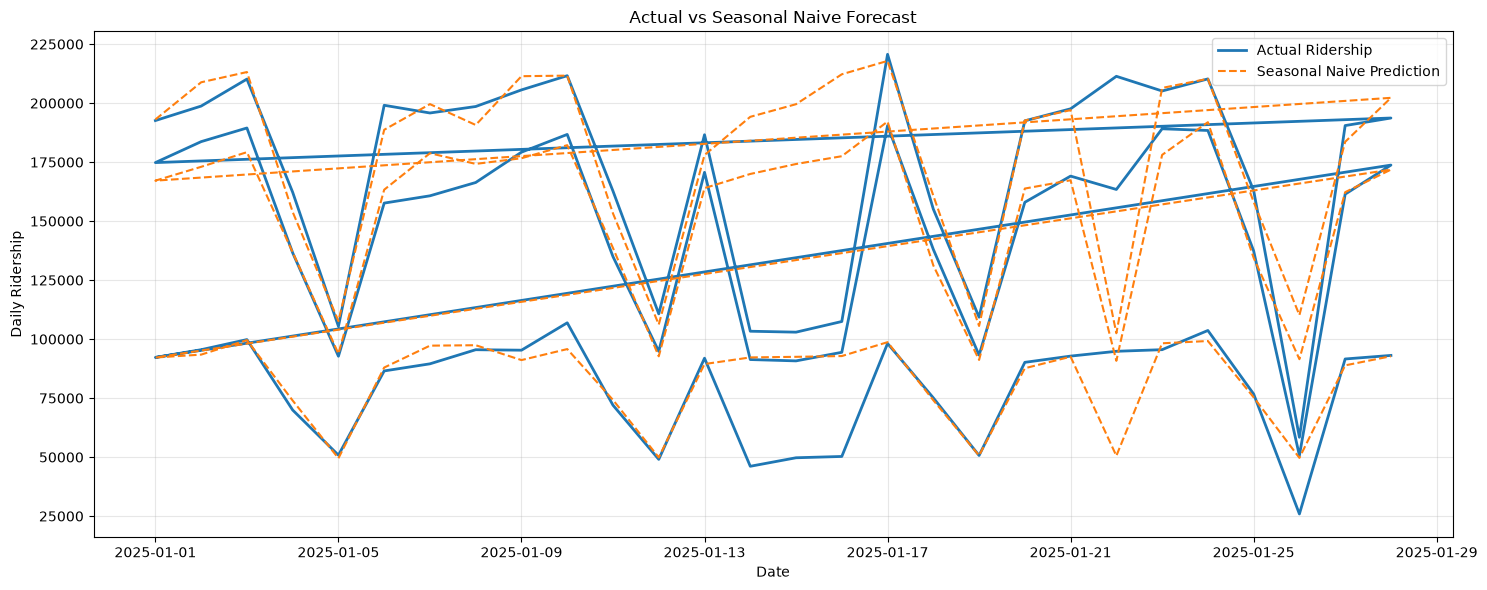

In [90]:
plt.figure(figsize=(15, 6))

plt.plot(
    evaluation_data['date'],
    evaluation_data['ridership'],
    label='Actual Ridership',
    linewidth=2
)

plt.plot(
    evaluation_data['date'],
    evaluation_data['seasonal_naive'],
    label='Seasonal Naive Prediction',
    linestyle='--'
)

plt.title('Actual vs Seasonal Naive Forecast')
plt.xlabel('Date')
plt.ylabel('Daily Ridership')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# SARIMAX Forecasting

In [91]:
sarimax_data = df_model[
    [
        'date',
        'line',
        'ridership',
        'day_of_week',
        'month',
        'is_weekend',
        'is_holiday',
        'is_special_event',
        'is_day_after_holiday',
        'days_since_open'
    ]
].copy()

sarimax_data = sarimax_data.sort_values(
    ['line', 'date']
).reset_index(drop=True)

print("Dataset Shape:", sarimax_data.shape)
display(sarimax_data.head())

Dataset Shape: (2669, 10)


,date,line,ridership,day_of_week,month,is_weekend,is_holiday,is_special_event,is_day_after_holiday,days_since_open
0,2022-07-01,Blue,143583.0,4,7,0,0,0,0,2738
1,2022-07-02,Blue,104646.0,5,7,1,0,0,0,2739
2,2022-07-03,Blue,73580.0,6,7,1,0,0,0,2740
3,2022-07-04,Blue,131317.0,0,7,0,0,0,0,2741
4,2022-07-05,Blue,125682.0,1,7,0,0,0,0,2742


In [92]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

In [93]:
!pip install statsmodels

In [94]:
def sarimax_forecast(data, forecast_start, horizon=28):

    forecast_start = pd.Timestamp(forecast_start)
    forecast_end = forecast_start + pd.Timedelta(days=horizon - 1)

    results = []

    exog_columns = [
        'day_of_week',
        'month',
        'is_weekend',
        'is_holiday',
        'is_special_event',
        'is_day_after_holiday',
        'days_since_open'
    ]

    for line in ['Blue', 'Green', 'Purple']:

        line_data = data[data['line'] == line].copy()
        line_data = line_data.set_index('date').sort_index()

        train = line_data[
            line_data.index < forecast_start
        ]

        future = line_data[
            (line_data.index >= forecast_start) &
            (line_data.index <= forecast_end)
        ]

        if len(future) != horizon:
            raise ValueError(
                f"Expected {horizon} future dates for {line}, "
                f"but found {len(future)}."
            )

        y_train = np.log1p(train['ridership'])

        X_train = train[exog_columns]
        X_future = future[exog_columns]

        model = SARIMAX(
            y_train,
            exog=X_train,
            order=(1, 0, 1),
            seasonal_order=(0, 1, 1, 7),
            enforce_stationarity=False,
            enforce_invertibility=False
        )

        fitted_model = model.fit(disp=False)

        predictions = fitted_model.forecast(
            steps=horizon,
            exog=X_future
        )

        predicted_ridership = np.expm1(predictions)
        predicted_ridership = predicted_ridership.clip(lower=0)

        line_forecast = pd.DataFrame({
            'date': future.index,
            'line': line,
            'actual_ridership': future['ridership'].values,
            'predicted_ridership': predicted_ridership.values
        })

        results.append(line_forecast)

    return pd.concat(results, ignore_index=True)

In [95]:
sarimax_predictions = sarimax_forecast(
    sarimax_data,
    forecast_start='2025-01-01',
    horizon=28
)

display(sarimax_predictions.head(10))

C:\Users\santhosh\anaconda3\envs\metro_ml\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
C:\Users\santhosh\anaconda3\envs\metro_ml\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
C:\Users\santhosh\anaconda3\envs\metro_ml\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
C:\Users\santhosh\anaconda3\envs\metro_ml\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
C:\Users\santhosh\anaconda3\envs\metro_ml\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: Converge

,date,line,actual_ridership,predicted_ridership
0,2025-01-01,Blue,192616.0,207928.670792
1,2025-01-02,Blue,198752.0,213838.265096
2,2025-01-03,Blue,210189.0,217107.530914
3,2025-01-04,Blue,162237.0,160903.322196
4,2025-01-05,Blue,105430.0,112955.643278
5,2025-01-06,Blue,199093.0,189681.498110
6,2025-01-07,Blue,195823.0,212746.307815
7,2025-01-08,Blue,198570.0,206971.478016
8,2025-01-09,Blue,205605.0,214013.459481
9,2025-01-10,Blue,211627.0,217672.723189


In [96]:
network_forecast = (
    sarimax_predictions.groupby('date')
    [['actual_ridership', 'predicted_ridership']]
    .sum()
    .reset_index()
)

display(network_forecast.head())

,date,actual_ridership,predicted_ridership
0,2025-01-01,459664.0,464098.219338
1,2025-01-02,477952.0,473378.353856
2,2025-01-03,499461.0,484403.387216
3,2025-01-04,368763.0,357389.184413
4,2025-01-05,249003.0,250668.386926


In [97]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

actual = network_forecast['actual_ridership']
predicted = network_forecast['predicted_ridership']

mae = mean_absolute_error(actual, predicted)

rmse = np.sqrt(
    mean_squared_error(actual, predicted)
)

mape = np.mean(
    np.abs((actual - predicted) / actual)
) * 100

print(f"MAE:  {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"MAPE: {mape:.2f}%")

MAE:  11816.44
RMSE: 14265.96
MAPE: 3.01%


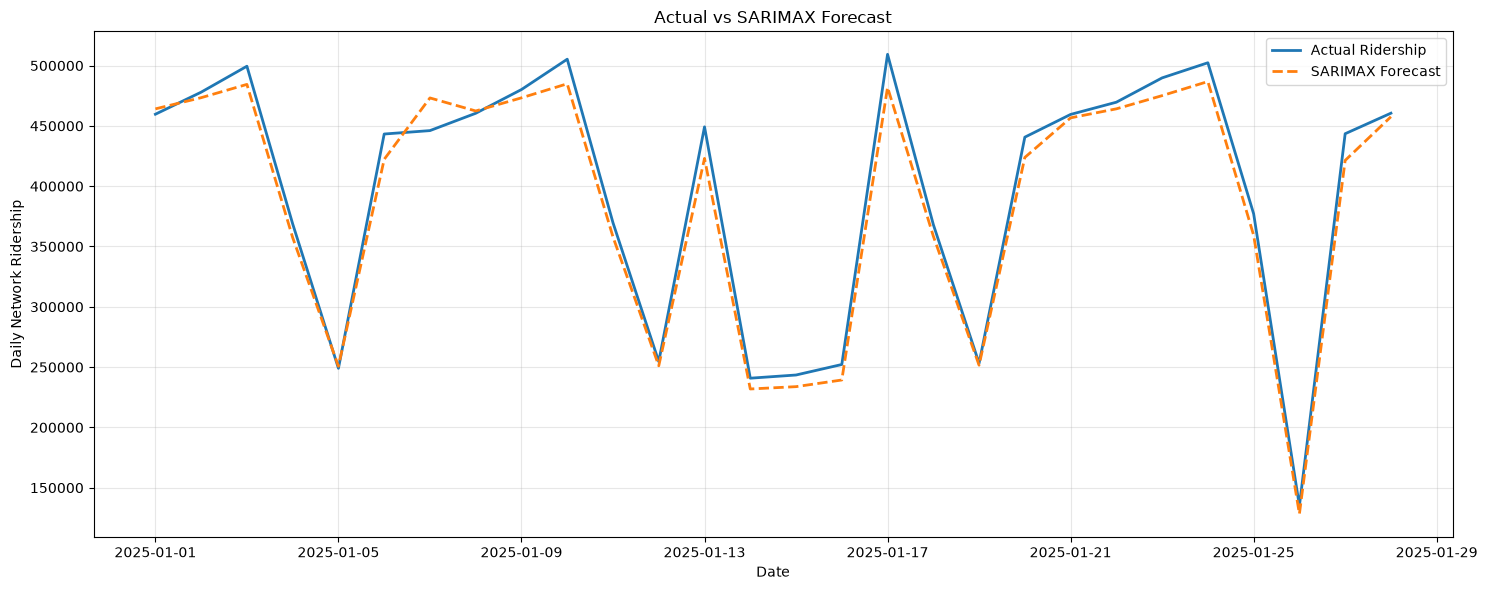

In [98]:
plt.figure(figsize=(15, 6))

plt.plot(
    network_forecast['date'],
    network_forecast['actual_ridership'],
    label='Actual Ridership',
    linewidth=2
)

plt.plot(
    network_forecast['date'],
    network_forecast['predicted_ridership'],
    label='SARIMAX Forecast',
    linestyle='--',
    linewidth=2
)

plt.title('Actual vs SARIMAX Forecast')
plt.xlabel('Date')
plt.ylabel('Daily Network Ridership')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# LightGBM Forecasting.

In [99]:
!pip install lightgbm

In [103]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [104]:
import lightgbm

print("LightGBM Version:", lightgbm.__version__)

LightGBM Version: 4.7.0


In [109]:
lgbm_data = model_data.copy()

# Keep date separately for validation and plotting
lgbm_dates = lgbm_data['date'].copy()

# Select only required numerical features
lgbm_data = lgbm_data[feature_columns + ['line', 'ridership']]

# Convert line into numerical columns
lgbm_data = pd.get_dummies(
    lgbm_data,
    columns=['line'],
    dtype=int
)

print(lgbm_data.head())

   day_of_week  day  month  quarter  year  week_of_year  is_weekend  \
0            3   25      8        3  2022            34           0   
1            3   25      8        3  2022            34           0   
2            4   26      8        3  2022            34           0   
3            4   26      8        3  2022            34           0   
4            5   27      8        3  2022            34           1   

   is_holiday  is_special_event  is_day_after_holiday  ...  ridership_lag_35  \
0           0                 0                     0  ...          138311.0   
1           0                 0                     0  ...          120656.0   
2           0                 0                     0  ...          113715.0   
3           0                 0                     0  ...          139604.0   
4           0                 0                     0  ...           99589.0   

   ridership_lag_42  ridership_lag_49  ridership_rolling_mean_7  \
0          133551.0      

In [110]:
line_columns = ['line_Blue', 'line_Green', 'line_Purple']

lgbm_feature_columns = feature_columns + line_columns

X = lgbm_data[lgbm_feature_columns].copy()
y = lgbm_data['ridership'].copy()

print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nFeature Data Types:")
print(X.dtypes)


Feature Shape: (2504, 23)
Target Shape: (2504,)

Feature Data Types:
day_of_week                    int32
day                            int32
month                          int32
quarter                        int32
year                           int32
week_of_year                   int32
is_weekend                     int32
is_holiday                     int32
is_special_event               int32
is_day_after_holiday           int32
days_since_open                int64
purple_open                    int32
purple_ramp                    int32
ridership_lag_28             float64
ridership_lag_35             float64
ridership_lag_42             float64
ridership_lag_49             float64
ridership_rolling_mean_7     float64
ridership_rolling_mean_14    float64
ridership_rolling_mean_28    float64
line_Blue                      int32
line_Green                     int32
line_Purple                    int32
dtype: object


In [112]:
print("Non-numeric columns:")
print(X.select_dtypes(exclude=np.number).columns.tolist())

print("\nMissing feature values:", X.isnull().sum().sum())
print("Missing target values:", y.isnull().sum())
print("Infinite values:", np.isinf(X.to_numpy(dtype=float)).sum())

Non-numeric columns:
[]

Missing feature values: 0
Missing target values: 0
Infinite values: 0


In [113]:
validation_start = pd.Timestamp('2025-01-01')
validation_end = pd.Timestamp('2025-01-28')

train_mask = lgbm_dates < validation_start

validation_mask = (
    (lgbm_dates >= validation_start) &
    (lgbm_dates <= validation_end)
)

X_train = X.loc[train_mask]
y_train = y.loc[train_mask]

X_val = X.loc[validation_mask]
y_val = y.loc[validation_mask]

print("Training Records:", len(X_train))
print("Validation Records:", len(X_val))

Training Records: 1961
Validation Records: 84


In [114]:
from lightgbm import LGBMRegressor

lgbm_model = LGBMRegressor(
    objective='regression',
    n_estimators=500,
    learning_rate=0.03,
    max_depth=7,
    num_leaves=31,
    random_state=42,
    n_jobs=1,
    verbosity=-1
)

In [115]:
lgbm_model.fit(X_train, y_train)

print("LightGBM model training completed!")

LightGBM model training completed!


In [116]:
y_pred = lgbm_model.predict(X_val)

y_pred = np.maximum(y_pred, 0)

print("Predictions generated:", len(y_pred))

Predictions generated: 84


# Evaluate the model

In [117]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

mae = mean_absolute_error(y_val, y_pred)

rmse = np.sqrt(mean_squared_error(y_val, y_pred))

mape = np.mean(
    np.abs((y_val.to_numpy() - y_pred) / y_val.to_numpy())
) * 100

print("LightGBM Evaluation Results")
print("---------------------------")
print("MAE :", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("MAPE:", round(mape, 2), "%")

LightGBM Evaluation Results
---------------------------
MAE : 6700.22
RMSE: 8845.08
MAPE: 5.41 %


In [118]:
validation_results = pd.DataFrame({
    'date': lgbm_dates.loc[validation_mask].values,
    'line': model_data.loc[validation_mask, 'line'].values,
    'actual': y_val.values,
    'predicted': y_pred
})

validation_results.head(10)

,date,line,actual,predicted
0,2025-01-01,Purple,92241.0,93408.173158
1,2025-01-01,Green,174807.0,185968.010171
2,2025-01-01,Blue,192616.0,199504.582662
3,2025-01-02,Purple,95515.0,96695.797399
4,2025-01-02,Green,183685.0,191363.114300
5,2025-01-02,Blue,198752.0,207328.044264
6,2025-01-03,Purple,99803.0,94768.702142
7,2025-01-03,Green,189469.0,187568.517242
8,2025-01-03,Blue,210189.0,201005.121043
9,2025-01-04,Blue,162237.0,173349.778474


In [119]:
network_results = validation_results.groupby('date').agg(
    actual=('actual', 'sum'),
    predicted=('predicted', 'sum')
).reset_index()

network_mae = mean_absolute_error(
    network_results['actual'],
    network_results['predicted']
)

network_rmse = np.sqrt(mean_squared_error(
    network_results['actual'],
    network_results['predicted']
))

network_mape = np.mean(
    np.abs(
        (network_results['actual'] - network_results['predicted'])
        / network_results['actual']
    )
) * 100

print("Network-Level Evaluation")
print("------------------------")
print("MAE :", round(network_mae, 2))
print("RMSE:", round(network_rmse, 2))
print("MAPE:", round(network_mape, 2), "%")

Network-Level Evaluation
------------------------
MAE : 16890.31
RMSE: 19112.69
MAPE: 4.73 %


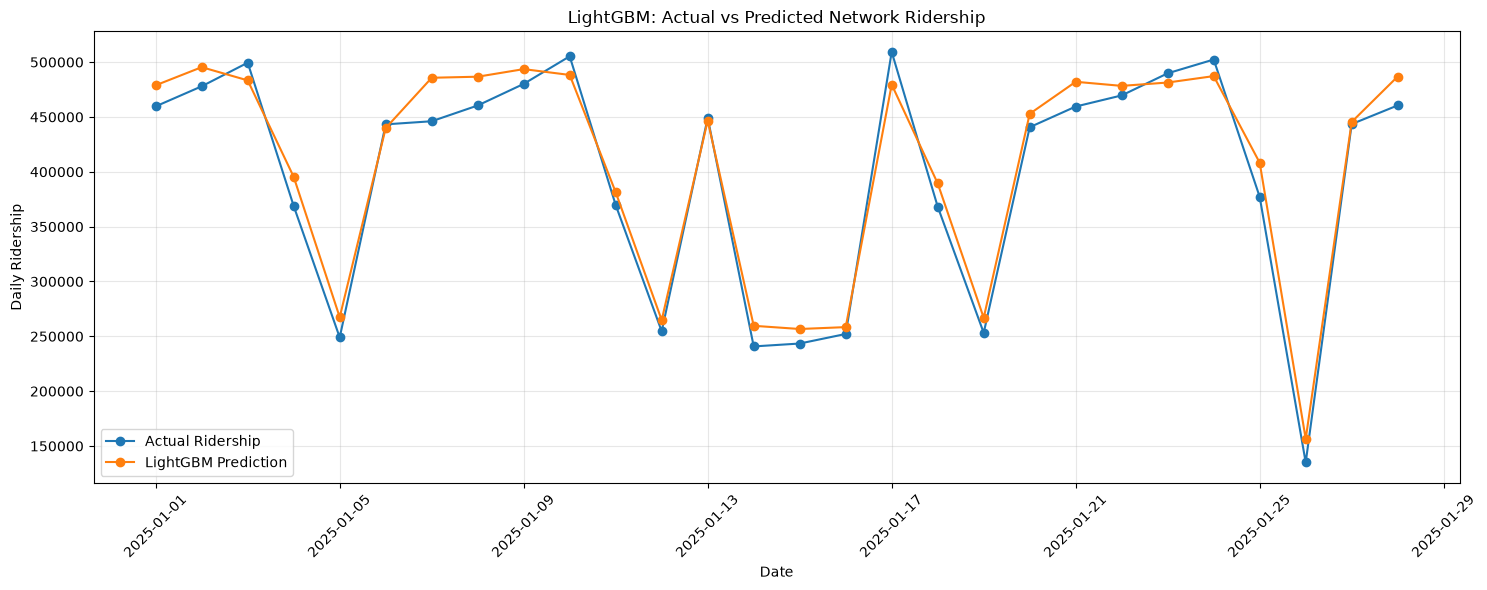

In [120]:
plt.figure(figsize=(15, 6))

plt.plot(
    network_results['date'],
    network_results['actual'],
    label='Actual Ridership',
    marker='o'
)

plt.plot(
    network_results['date'],
    network_results['predicted'],
    label='LightGBM Prediction',
    marker='o'
)

plt.title('LightGBM: Actual vs Predicted Network Ridership')
plt.xlabel('Date')
plt.ylabel('Daily Ridership')
plt.legend()
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [121]:
importance_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': lgbm_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

importance_df

,Feature,Importance
13,ridership_lag_28,1312
14,ridership_lag_35,1239
16,ridership_lag_49,1158
15,ridership_lag_42,1128
10,days_since_open,1088
1,day,820
5,week_of_year,767
0,day_of_week,648
17,ridership_rolling_mean_7,612
18,ridership_rolling_mean_14,568


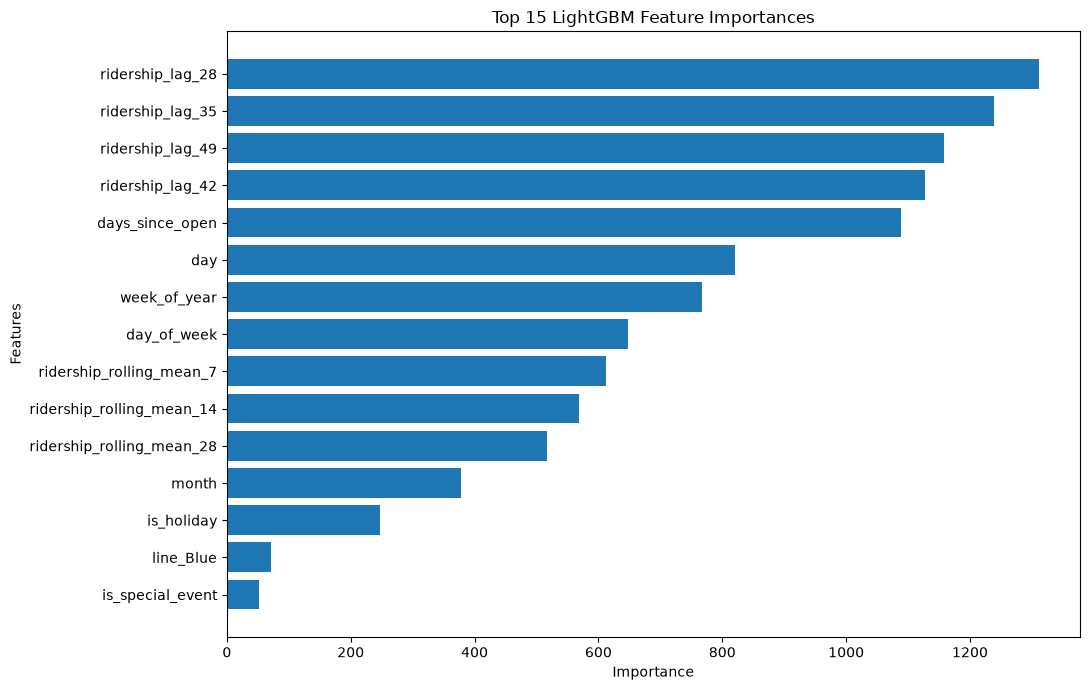

In [122]:
plt.figure(figsize=(11, 7))

top_features = importance_df.head(15).sort_values('Importance')

plt.barh(
    top_features['Feature'],
    top_features['Importance']
)

plt.title('Top 15 LightGBM Feature Importances')
plt.xlabel('Importance')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

# Rolling-Origin Backtesting

In [131]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from lightgbm import LGBMRegressor

from statsmodels.tsa.statespace.sarimax import SARIMAX

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

import warnings
warnings.filterwarnings('ignore')

In [132]:
validation_windows = [
    ('2024-12-04', '2024-12-31'),
    ('2025-01-01', '2025-01-28'),
    ('2025-01-29', '2025-02-25'),
    ('2025-02-26', '2025-03-25')
]

for i, (start, end) in enumerate(validation_windows, 1):
    print(f"Window {i}: {start} to {end}")

Window 1: 2024-12-04 to 2024-12-31
Window 2: 2025-01-01 to 2025-01-28
Window 3: 2025-01-29 to 2025-02-25
Window 4: 2025-02-26 to 2025-03-25


In [133]:
backtest_data = model_data.copy()

backtest_data = backtest_data.sort_values(
    ['date', 'line']
).reset_index(drop=True)

print("Dataset Shape:", backtest_data.shape)
print("Date Range:", backtest_data['date'].min(),
      "to", backtest_data['date'].max())

print("\nRecords per line:")
print(backtest_data['line'].value_counts())

Dataset Shape: (2504, 29)
Date Range: 2022-08-25 00:00:00 to 2025-06-30 00:00:00

Records per line:
line
Blue      1041
Green     1041
Purple     422
Name: count, dtype: int64


In [135]:
lgbm_backtest_data = pd.get_dummies(
    backtest_data,
    columns=['line'],
    dtype=int
)

line_columns = [
    'line_Blue',
    'line_Green',
    'line_Purple'
]

backtest_feature_columns = feature_columns + line_columns

X_backtest = lgbm_backtest_data[
    backtest_feature_columns
].copy()

y_backtest = lgbm_backtest_data['ridership'].copy()

print("Feature Shape:", X_backtest.shape)
print("Target Shape:", y_backtest.shape)

print("\nNon-numeric features:")
print(X_backtest.select_dtypes(exclude=np.number).columns.tolist())

Feature Shape: (2504, 23)
Target Shape: (2504,)

Non-numeric features:
[]


In [136]:
def calculate_metrics(actual, predicted):

    actual = np.asarray(actual)
    predicted = np.asarray(predicted)

    mae = mean_absolute_error(actual, predicted)

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    mape = np.mean(
        np.abs((actual - predicted) / actual)
    ) * 100

    return {
        'MAE': mae,
        'RMSE': rmse,
        'MAPE': mape
    }

In [139]:
def run_sarimax_backtest(data, forecast_start, forecast_end):

    from statsmodels.tsa.statespace.sarimax import SARIMAX

    sarimax_features = [
        'day_of_week',
        'month',
        'is_weekend',
        'is_holiday',
        'is_special_event',
        'is_day_after_holiday',
        'days_since_open'
    ]

    results = []

    for line in ['Blue', 'Green', 'Purple']:

        # --------------------------------
        # FILTER LINE DATA
        # --------------------------------
        line_data = data[data['line'] == line].copy()

        line_data['date'] = pd.to_datetime(line_data['date'])

        line_data = line_data.sort_values('date')

        # --------------------------------
        # TRAINING DATA
        # --------------------------------
        train = line_data[
            line_data['date'] < forecast_start
        ].copy()

        # Set date as the time-series index
        train = train.set_index('date').asfreq('D')

        # --------------------------------
        # FUTURE VALIDATION DATA
        # --------------------------------
        future = line_data[
            (line_data['date'] >= forecast_start) &
            (line_data['date'] <= forecast_end)
        ].copy()

        future = future.sort_values('date')

        if len(future) != 28:
            raise ValueError(
                f"{line}: Expected 28 validation days, found {len(future)}"
            )

        future = future.set_index('date')

        # --------------------------------
        # TARGET TRANSFORMATION
        # --------------------------------
        y_train = np.log1p(train['ridership'])

        X_train = train[sarimax_features]
        X_future = future[sarimax_features]

        # --------------------------------
        # TRAIN SARIMAX
        # --------------------------------
        model = SARIMAX(
            endog=y_train,
            exog=X_train,
            order=(1, 0, 1),
            seasonal_order=(0, 1, 1, 7),
            enforce_stationarity=False,
            enforce_invertibility=False
        )

        fitted_model = model.fit(
            disp=False,
            maxiter=100
        )

        # --------------------------------
        # FORECAST
        # --------------------------------
        predictions = fitted_model.forecast(
            steps=len(future),
            exog=X_future
        )

        predictions = np.expm1(predictions)
        predictions = np.maximum(predictions, 0)

        # --------------------------------
        # STORE RESULTS
        # --------------------------------
        line_results = pd.DataFrame({
            'date': future.index,
            'line': line,
            'actual': future['ridership'].values,
            'predicted': predictions.values
        })

        results.append(line_results)

    return pd.concat(results, ignore_index=True)

In [140]:
backtest_runs = []

for window_number, (start, end) in enumerate(
    validation_windows, 1
):

    forecast_start = pd.Timestamp(start)
    forecast_end = pd.Timestamp(end)

    print(f"\n{'='*45}")
    print(f"VALIDATION WINDOW {window_number}")
    print(f"Period: {start} to {end}")
    print(f"{'='*45}")

    # --------------------------------
    # Prepare training and validation
    # --------------------------------

    train_mask = (
        backtest_data['date'] < forecast_start
    )

    validation_mask = (
        (backtest_data['date'] >= forecast_start) &
        (backtest_data['date'] <= forecast_end)
    )

    X_train = X_backtest.loc[train_mask]
    y_train = y_backtest.loc[train_mask]

    X_val = X_backtest.loc[validation_mask]

    validation_data = backtest_data.loc[
        validation_mask,
        ['date', 'line', 'ridership', 'ridership_lag_28']
    ].copy()

    validation_data = validation_data.rename(
        columns={'ridership': 'actual'}
    )

    if len(validation_data) != 84:
        raise ValueError(
            f"Expected 84 validation records, "
            f"but found {len(validation_data)}"
        )

    # --------------------------------
    # MODEL 1: Seasonal Naive
    # --------------------------------

    naive_results = validation_data[
        ['date', 'line', 'actual']
    ].copy()

    naive_results['predicted'] = (
        validation_data['ridership_lag_28'].values
    )

    naive_results['model'] = 'Seasonal Naive'

    # --------------------------------
    # MODEL 2: SARIMAX
    # --------------------------------

    sarimax_results = run_sarimax_backtest(
        df_model,
        forecast_start,
        forecast_end
    )

    sarimax_results['model'] = 'SARIMAX'

    # --------------------------------
    # MODEL 3: LightGBM
    # --------------------------------

    lgbm_model = LGBMRegressor(
        objective='regression',
        n_estimators=500,
        learning_rate=0.03,
        max_depth=7,
        num_leaves=31,
        random_state=42,
        n_jobs=1,
        verbosity=-1
    )

    lgbm_model.fit(
        X_train,
        y_train
    )

    lgbm_predictions = np.maximum(
        lgbm_model.predict(X_val),
        0
    )

    lgbm_results = validation_data[
        ['date', 'line', 'actual']
    ].copy()

    lgbm_results['predicted'] = lgbm_predictions

    lgbm_results['model'] = 'LightGBM'

    # --------------------------------
    # Combine the three model results
    # --------------------------------

    window_results = pd.concat(
        [
            naive_results,
            sarimax_results,
            lgbm_results
        ],
        ignore_index=True
    )

    window_results['window'] = window_number

    backtest_runs.append(window_results)

    print("Training records:", len(X_train))
    print("Validation records:", len(validation_data))
    print("Completed models: Seasonal Naive, SARIMAX, LightGBM")
    print("Window completed successfully!")


VALIDATION WINDOW 1
Period: 2024-12-04 to 2024-12-31
Training records: 1877
Validation records: 84
Completed models: Seasonal Naive, SARIMAX, LightGBM
Window completed successfully!

VALIDATION WINDOW 2
Period: 2025-01-01 to 2025-01-28
Training records: 1961
Validation records: 84
Completed models: Seasonal Naive, SARIMAX, LightGBM
Window completed successfully!

VALIDATION WINDOW 3
Period: 2025-01-29 to 2025-02-25
Training records: 2045
Validation records: 84
Completed models: Seasonal Naive, SARIMAX, LightGBM
Window completed successfully!

VALIDATION WINDOW 4
Period: 2025-02-26 to 2025-03-25
Training records: 2129
Validation records: 84
Completed models: Seasonal Naive, SARIMAX, LightGBM
Window completed successfully!


In [141]:
print("Completed Windows:", len(backtest_runs))

for i, result in enumerate(backtest_runs, 1):

    print(f"\nWindow {i}")
    print("Records:", len(result))
    print(result['model'].value_counts())

Completed Windows: 4

Window 1
Records: 252
model
Seasonal Naive    84
SARIMAX           84
LightGBM          84
Name: count, dtype: int64

Window 2
Records: 252
model
Seasonal Naive    84
SARIMAX           84
LightGBM          84
Name: count, dtype: int64

Window 3
Records: 252
model
Seasonal Naive    84
SARIMAX           84
LightGBM          84
Name: count, dtype: int64

Window 4
Records: 252
model
Seasonal Naive    84
SARIMAX           84
LightGBM          84
Name: count, dtype: int64


# LightGBM Hyperparameter Tuning

In [142]:
parameter_options = [
    {
        'n_estimators': 300,
        'learning_rate': 0.03,
        'max_depth': 5,
        'num_leaves': 15
    },
    {
        'n_estimators': 500,
        'learning_rate': 0.03,
        'max_depth': 7,
        'num_leaves': 31
    },
    {
        'n_estimators': 700,
        'learning_rate': 0.02,
        'max_depth': 8,
        'num_leaves': 31
    },
    {
        'n_estimators': 500,
        'learning_rate': 0.05,
        'max_depth': 6,
        'num_leaves': 25
    }
]

In [144]:
tuning_results = []

for option_number, params in enumerate(parameter_options, start=1):

    window_mapes = []

    print(f"Testing Combination {option_number}")

    for forecast_start, forecast_end in validation_windows:

        train_mask = (
            lgbm_backtest_data['date'] < forecast_start
        )

        validation_mask = (
            (lgbm_backtest_data['date'] >= forecast_start) &
            (lgbm_backtest_data['date'] <= forecast_end)
        )

        X_train = lgbm_backtest_data.loc[
            train_mask, lgbm_feature_columns
        ]

        y_train = lgbm_backtest_data.loc[
            train_mask, 'ridership'
        ]

        X_validation = lgbm_backtest_data.loc[
            validation_mask, lgbm_feature_columns
        ]

        validation = lgbm_backtest_data.loc[
            validation_mask,
            ['date', 'ridership',
             'line_Blue', 'line_Green', 'line_Purple']
        ].copy()

        # Reconstruct original line names
        validation['line'] = np.select(
            [
                validation['line_Blue'] == 1,
                validation['line_Green'] == 1,
                validation['line_Purple'] == 1
            ],
            ['Blue', 'Green', 'Purple'],
            default='Unknown'
        )

        model = LGBMRegressor(
            objective='regression',
            random_state=42,
            n_jobs=1,
            verbosity=-1,
            **params
        )

        model.fit(X_train, y_train)

        validation['predicted'] = model.predict(X_validation)

        # Network-level evaluation
        network_actual = validation.groupby('date')[
            'ridership'
        ].sum()

        network_predicted = validation.groupby('date')[
            'predicted'
        ].sum()

        mape = mean_absolute_percentage_error(
            network_actual,
            network_predicted
        ) * 100

        window_mapes.append(mape)

    tuning_results.append({
        'combination': option_number,
        **params,
        'average_mape': np.mean(window_mapes)
    })

    print(f"Average MAPE: {np.mean(window_mapes):.2f}%")

Testing Combination 1
Average MAPE: 3.14%
Testing Combination 2
Average MAPE: 2.98%
Testing Combination 3
Average MAPE: 2.85%
Testing Combination 4
Average MAPE: 3.11%


In [145]:
tuning_df = pd.DataFrame(tuning_results)

tuning_df = tuning_df.sort_values(
    'average_mape'
).reset_index(drop=True)

display(tuning_df)

,combination,n_estimators,learning_rate,max_depth,num_leaves,average_mape
0,3,700,0.02,8,31,2.853475
1,2,500,0.03,7,31,2.979241
2,4,500,0.05,6,25,3.110756
3,1,300,0.03,5,15,3.135952


In [146]:
best_parameters = {
    key: tuning_df.loc[0, key]
    for key in [
        'n_estimators',
        'learning_rate',
        'max_depth',
        'num_leaves'
    ]
}

print("Best Parameters:")
print(best_parameters)

print(
    f"\nBest Average MAPE: "
    f"{tuning_df.loc[0, 'average_mape']:.2f}%"
)

Best Parameters:
{'n_estimators': 700, 'learning_rate': 0.02, 'max_depth': 8, 'num_leaves': 31}

Best Average MAPE: 2.85%


#  Final Holdout Testing

In [147]:
holdout_windows = [
    ('2025-04-01', '2025-04-28'),
    ('2025-04-29', '2025-05-26'),
    ('2025-05-27', '2025-06-23')
]

In [148]:
holdout_data = lgbm_backtest_data.copy()

holdout_data['date'] = pd.to_datetime(
    holdout_data['date']
)

holdout_data = holdout_data.sort_values(
    'date'
).reset_index(drop=True)

print("Holdout data shape:", holdout_data.shape)
print("Holdout period: April 1 to June 23, 2025")

Holdout data shape: (2504, 31)
Holdout period: April 1 to June 23, 2025


In [149]:
holdout_results = []

for window_number, (forecast_start, forecast_end) in enumerate(
    holdout_windows, start=1
):

    print(f"\nProcessing Holdout Window {window_number}")
    print(f"{forecast_start} to {forecast_end}")

    # --------------------------------
    # TRAINING AND VALIDATION DATA
    # --------------------------------

    train_mask = (
        holdout_data['date'] < forecast_start
    )

    validation_mask = (
        (holdout_data['date'] >= forecast_start) &
        (holdout_data['date'] <= forecast_end)
    )

    X_train = holdout_data.loc[
        train_mask, lgbm_feature_columns
    ]

    y_train = holdout_data.loc[
        train_mask, 'ridership'
    ]

    X_validation = holdout_data.loc[
        validation_mask, lgbm_feature_columns
    ]

    validation = holdout_data.loc[
        validation_mask,
        ['date', 'ridership_lag_28',
         'ridership', 'line_Blue',
         'line_Green', 'line_Purple']
    ].copy()

    validation['line'] = np.select(
        [
            validation['line_Blue'] == 1,
            validation['line_Green'] == 1,
            validation['line_Purple'] == 1
        ],
        ['Blue', 'Green', 'Purple'],
        default='Unknown'
    )

    validation = validation.rename(
        columns={'ridership': 'actual'}
    )

    # --------------------------------
    # MODEL 1: SEASONAL NAIVE
    # --------------------------------

    seasonal_results = validation[
        ['date', 'line', 'actual']
    ].copy()

    seasonal_results['predicted'] = (
        validation['ridership_lag_28'].values
    )

    seasonal_results['model'] = 'Seasonal Naive'

    # --------------------------------
    # MODEL 2: SARIMAX
    # --------------------------------

    sarimax_results = run_sarimax_backtest(
        df_model,
        forecast_start,
        forecast_end
    )

    sarimax_results['model'] = 'SARIMAX'

    # --------------------------------
    # MODEL 3: TUNED LIGHTGBM
    # --------------------------------

    lgbm_model = LGBMRegressor(
        objective='regression',
        random_state=42,
        n_jobs=1,
        verbosity=-1,
        **best_parameters
    )

    lgbm_model.fit(X_train, y_train)

    lgbm_results = validation[
        ['date', 'line', 'actual']
    ].copy()

    lgbm_results['predicted'] = (
        lgbm_model.predict(X_validation)
    )

    lgbm_results['model'] = 'LightGBM'

    # --------------------------------
    # COMBINE RESULTS
    # --------------------------------

    window_results = pd.concat(
        [
            seasonal_results,
            sarimax_results,
            lgbm_results
        ],
        ignore_index=True
    )

    window_results['window'] = window_number

    holdout_results.append(window_results)

    print("Window completed.")


Processing Holdout Window 1
2025-04-01 to 2025-04-28
Window completed.

Processing Holdout Window 2
2025-04-29 to 2025-05-26
Window completed.

Processing Holdout Window 3
2025-05-27 to 2025-06-23
Window completed.


In [150]:
holdout_predictions = pd.concat(
    holdout_results,
    ignore_index=True
)

print("Total prediction records:", len(holdout_predictions))

display(holdout_predictions.head())

Total prediction records: 756


,date,line,actual,predicted,model,window
0,2025-04-01,Blue,199292.0,202530.0,Seasonal Naive,1
1,2025-04-01,Green,173035.0,172176.0,Seasonal Naive,1
2,2025-04-01,Purple,95132.0,97093.0,Seasonal Naive,1
3,2025-04-02,Blue,207878.0,206482.0,Seasonal Naive,1
4,2025-04-02,Green,178668.0,178123.0,Seasonal Naive,1


In [151]:
holdout_network = (
    holdout_predictions
    .groupby(['window', 'date', 'model'])[
        ['actual', 'predicted']
    ]
    .sum()
    .reset_index()
)

final_metrics = []

for model_name in holdout_network['model'].unique():

    model_data = holdout_network[
        holdout_network['model'] == model_name
    ]

    actual = model_data['actual']
    predicted = model_data['predicted']

    final_metrics.append({
        'Model': model_name,
        'MAE': np.mean(np.abs(actual - predicted)),
        'RMSE': np.sqrt(np.mean((actual - predicted) ** 2)),
        'MAPE': np.mean(
            np.abs((actual - predicted) / actual)
        ) * 100
    })

final_metrics_df = pd.DataFrame(final_metrics)

final_metrics_df = final_metrics_df.sort_values(
    'MAPE'
).reset_index(drop=True)

display(final_metrics_df.round(2))

,Model,MAE,RMSE,MAPE
0,SARIMAX,10333.29,20004.86,2.50
1,LightGBM,13477.23,21268.51,3.34
2,Seasonal Naive,26223.62,59703.64,6.76


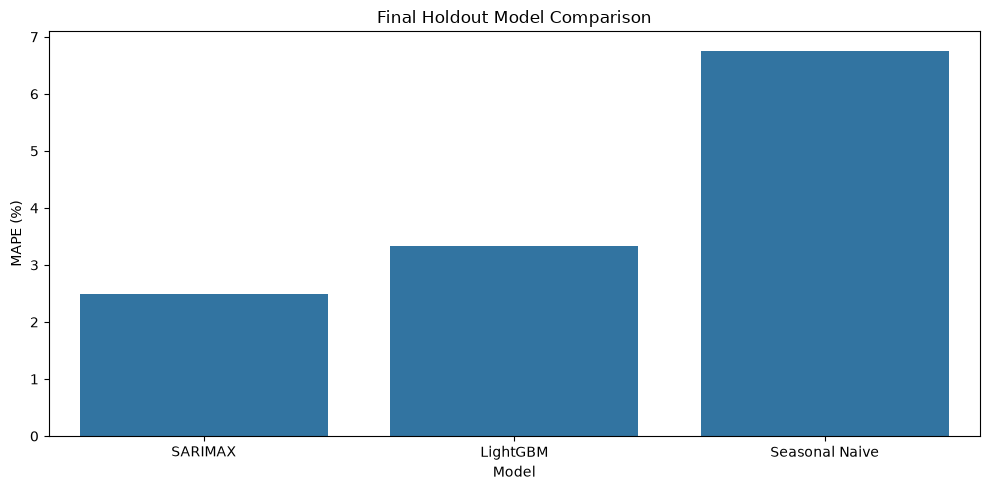

In [152]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=final_metrics_df,
    x='Model',
    y='MAPE'
)

plt.title('Final Holdout Model Comparison')
plt.ylabel('MAPE (%)')
plt.xlabel('Model')
plt.tight_layout()
plt.show()

In [153]:
seasonal_mape = final_metrics_df.loc[
    final_metrics_df['Model'] == 'Seasonal Naive',
    'MAPE'
].iloc[0]

best_model = final_metrics_df.iloc[0]

improvement = (
    (seasonal_mape - best_model['MAPE'])
    / seasonal_mape
) * 100

print("Best Model:", best_model['Model'])
print(f"Final MAPE: {best_model['MAPE']:.2f}%")
print(f"Improvement over Seasonal Naive: {improvement:.2f}%")

print("\nProject Success Criteria:")

print(
    "MAPE <= 6%:",
    best_model['MAPE'] <= 6
)

print(
    "30% improvement over baseline:",
    improvement >= 30
)

Best Model: SARIMAX
Final MAPE: 2.50%
Improvement over Seasonal Naive: 63.07%

Project Success Criteria:
MAPE <= 6%: True
30% improvement over baseline: True


# Generate the Final 28-Day Ridership Forecast

In [154]:
forecast_start = pd.Timestamp('2025-07-01')
forecast_end = pd.Timestamp('2025-07-28')

forecast_dates = pd.date_range(
    start=forecast_start,
    end=forecast_end,
    freq='D'
)

print("Forecast Start:", forecast_start.date())
print("Forecast End:", forecast_end.date())
print("Forecast Days:", len(forecast_dates))

Forecast Start: 2025-07-01
Forecast End: 2025-07-28
Forecast Days: 28


In [155]:
future_rows = []

line_opening_dates = {
    'Blue': pd.Timestamp('2015-01-01'),
    'Green': pd.Timestamp('2015-01-01'),
    'Purple': pd.Timestamp('2024-03-11')
}

for line in ['Blue', 'Green', 'Purple']:

    line_history = (
        df_model[df_model['line'] == line]
        .set_index('date')['ridership']
        .sort_index()
    )

    for date in forecast_dates:

        row = {}

        # Calendar features
        row['date'] = date
        row['line'] = line

        row['day_of_week'] = date.dayofweek
        row['day'] = date.day
        row['month'] = date.month
        row['quarter'] = date.quarter
        row['year'] = date.year
        row['week_of_year'] = date.isocalendar().week

        row['is_weekend'] = int(date.dayofweek in [5, 6])

        # Assumptions: no known future holiday/event data
        row['is_holiday'] = 0
        row['is_special_event'] = 0
        row['is_day_after_holiday'] = 0

        # Line information
        opening_date = line_opening_dates[line]

        row['days_since_open'] = (
            date - opening_date
        ).days

        row['purple_open'] = int(line == 'Purple')

        row['purple_ramp'] = int(
            line == 'Purple' and
            row['days_since_open'] <= 90
        )

        # Historical lag features
        for lag in [28, 35, 42, 49]:

            lag_date = date - pd.Timedelta(days=lag)

            row[f'ridership_lag_{lag}'] = (
                line_history.loc[lag_date]
            )

        # Historical rolling averages
        for window in [7, 14, 28]:

            end_date = date - pd.Timedelta(days=28)

            rolling_dates = pd.date_range(
                end=end_date,
                periods=window,
                freq='D'
            )

            row[f'ridership_rolling_mean_{window}'] = (
                line_history.reindex(rolling_dates).mean()
            )

        future_rows.append(row)

future_data = pd.DataFrame(future_rows)

print("Future Data Shape:", future_data.shape)

display(future_data.head())

Future Data Shape: (84, 22)


,date,line,day_of_week,day,month,quarter,year,week_of_year,is_weekend,is_holiday,...,days_since_open,purple_open,purple_ramp,ridership_lag_28,ridership_lag_35,ridership_lag_42,ridership_lag_49,ridership_rolling_mean_7,ridership_rolling_mean_14,ridership_rolling_mean_28
0,2025-07-01,Blue,1,1,7,3,2025,27,0,0,...,3834,0,0,201028.0,210798.0,211055.0,201063.0,189177.857143,187192.214286,187134.250000
1,2025-07-02,Blue,2,2,7,3,2025,27,0,0,...,3835,0,0,206832.0,210527.0,156751.0,195540.0,188650.000000,190769.428571,186850.392857
2,2025-07-03,Blue,3,3,7,3,2025,27,0,0,...,3836,0,0,221453.0,215236.0,217953.0,205581.0,189538.142857,191019.428571,187182.392857
3,2025-07-04,Blue,4,4,7,3,2025,27,0,0,...,3837,0,0,219696.0,215717.0,223878.0,224502.0,190106.571429,190720.714286,186969.928571
4,2025-07-05,Blue,5,5,7,3,2025,27,1,0,...,3838,0,0,169279.0,167995.0,170393.0,166681.0,190290.000000,190641.142857,187021.857143


In [156]:
future_encoded = pd.get_dummies(
    future_data,
    columns=['line'],
    dtype=int
)

for col in lgbm_feature_columns:

    if col not in future_encoded.columns:
        future_encoded[col] = 0

X_future = future_encoded[
    lgbm_feature_columns
]

print("Future Input Shape:", X_future.shape)

Future Input Shape: (84, 23)


In [157]:
final_train_mask = (
    lgbm_backtest_data['date'] <= '2025-06-30'
)

X_final_train = lgbm_backtest_data.loc[
    final_train_mask,
    lgbm_feature_columns
]

y_final_train = lgbm_backtest_data.loc[
    final_train_mask,
    'ridership'
]

final_lgbm_model = LGBMRegressor(
    objective='regression',
    random_state=42,
    n_jobs=1,
    verbosity=-1,
    **best_parameters
)

final_lgbm_model.fit(
    X_final_train,
    y_final_train
)

print("Final LightGBM model trained successfully.")

Final LightGBM model trained successfully.


In [158]:
forecast_data = future_data[
    ['date', 'line']
].copy()

forecast_data['predicted_ridership'] = (
    final_lgbm_model.predict(X_future)
)

forecast_data['predicted_ridership'] = (
    forecast_data['predicted_ridership'].clip(lower=0)
)

display(forecast_data.head(10))

,date,line,predicted_ridership
0,2025-07-01,Blue,196679.616376
1,2025-07-02,Blue,198868.828160
2,2025-07-03,Blue,205131.191842
3,2025-07-04,Blue,219206.392572
4,2025-07-05,Blue,162700.460797
5,2025-07-06,Blue,115461.277590
6,2025-07-07,Blue,189988.299147
7,2025-07-08,Blue,203058.581515
8,2025-07-09,Blue,200179.455080
9,2025-07-10,Blue,213696.312204


In [159]:
network_forecast = (
    forecast_data.groupby('date')[
        'predicted_ridership'
    ]
    .sum()
    .reset_index()
)

network_forecast.rename(
    columns={
        'predicted_ridership': 'network_ridership'
    },
    inplace=True
)

display(network_forecast.head())

,date,network_ridership
0,2025-07-01,463281.544162
1,2025-07-02,464284.677935
2,2025-07-03,483736.267988
3,2025-07-04,499176.173318
4,2025-07-05,373584.045656


In [163]:
backtest_predictions = pd.concat(
    backtest_runs,
    ignore_index=True
)

print("Total records:", len(backtest_predictions))
print("Models:", backtest_predictions['model'].unique())
print("Validation windows:", backtest_predictions['window'].nunique())

display(backtest_predictions.head())

Total records: 1008
Models: ['Seasonal Naive' 'SARIMAX' 'LightGBM']
Validation windows: 4


,date,line,actual,predicted,model,window
0,2024-12-04,Blue,193071.0,188725.0,Seasonal Naive,1
1,2024-12-04,Green,167155.0,163686.0,Seasonal Naive,1
2,2024-12-04,Purple,92205.0,90195.0,Seasonal Naive,1
3,2024-12-05,Blue,208836.0,204747.0,Seasonal Naive,1
4,2024-12-05,Green,173011.0,168426.0,Seasonal Naive,1


In [162]:
print("backtest_runs:", 'backtest_runs' in globals())
print("backtest_predictions:", 'backtest_predictions' in globals())

backtest_runs: True
backtest_predictions: False


In [164]:
validation_residuals = backtest_predictions[
    backtest_predictions['model'] == 'LightGBM'
].copy()

validation_residuals['error'] = (
    validation_residuals['actual'] -
    validation_residuals['predicted']
)

lower_error = validation_residuals['error'].quantile(0.10)
upper_error = validation_residuals['error'].quantile(0.90)

network_forecast['lower_80'] = (
    network_forecast['network_ridership'] + lower_error
).clip(lower=0)

network_forecast['upper_80'] = (
    network_forecast['network_ridership'] + upper_error
)

display(network_forecast.head())

,date,network_ridership,lower_80,upper_80
0,2025-07-01,463281.544162,455330.310318,471973.051696
1,2025-07-02,464284.677935,456333.444091,472976.185470
2,2025-07-03,483736.267988,475785.034143,492427.775522
3,2025-07-04,499176.173318,491224.939474,507867.680853
4,2025-07-05,373584.045656,365632.811811,382275.553190


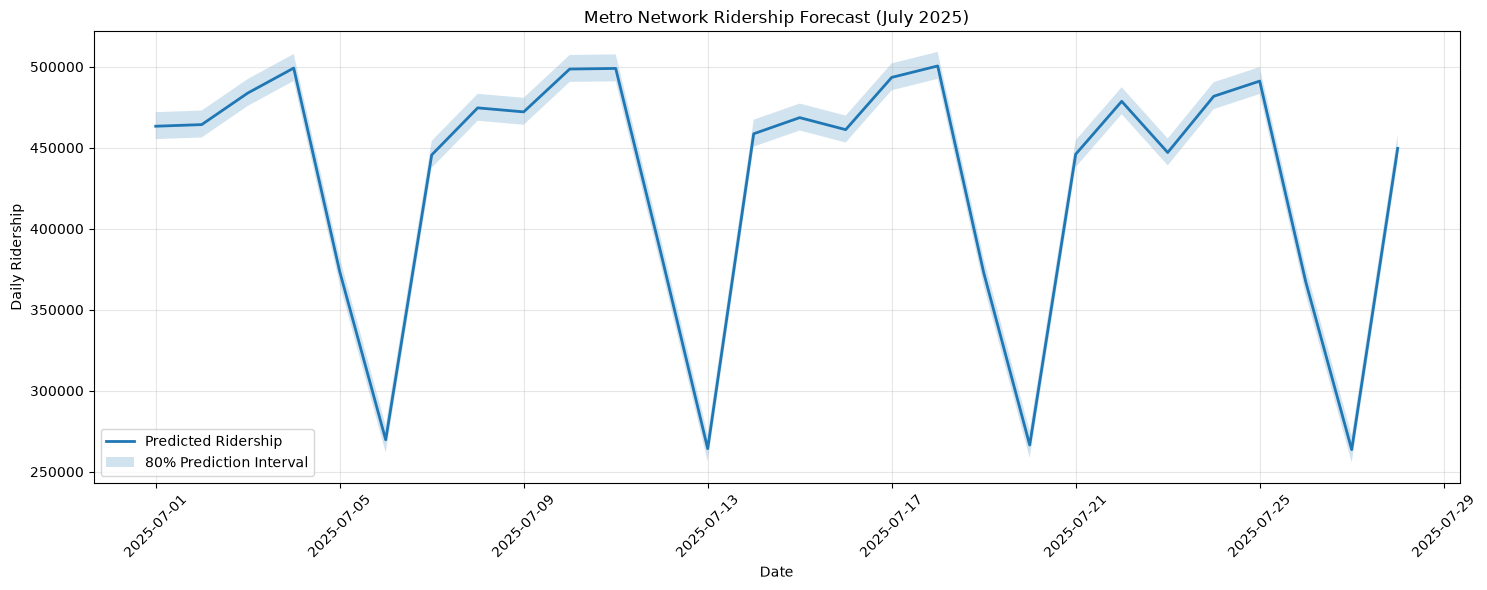

In [165]:
plt.figure(figsize=(15, 6))

plt.plot(
    network_forecast['date'],
    network_forecast['network_ridership'],
    label='Predicted Ridership',
    linewidth=2
)

plt.fill_between(
    network_forecast['date'],
    network_forecast['lower_80'],
    network_forecast['upper_80'],
    alpha=0.2,
    label='80% Prediction Interval'
)

plt.title('Metro Network Ridership Forecast (July 2025)')
plt.xlabel('Date')
plt.ylabel('Daily Ridership')
plt.legend()
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

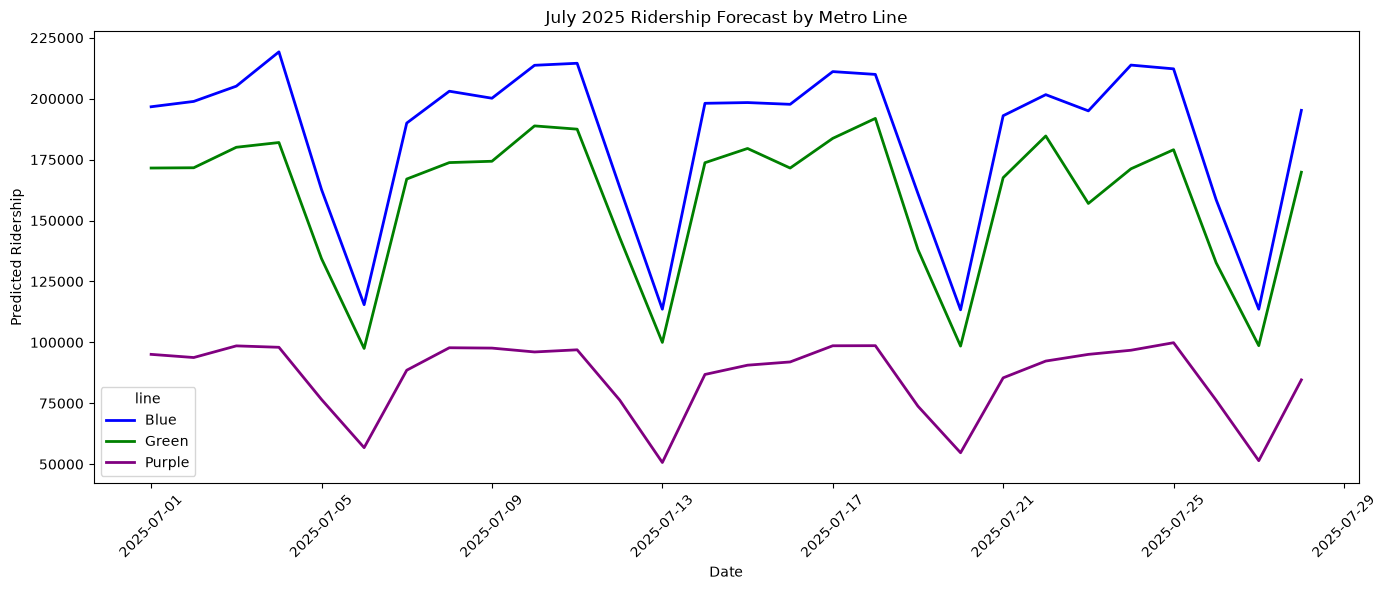

In [166]:
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=forecast_data,
    x='date',
    y='predicted_ridership',
    hue='line',
    palette=line_colors,
    linewidth=2
)

plt.title('July 2025 Ridership Forecast by Metro Line')
plt.xlabel('Date')
plt.ylabel('Predicted Ridership')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Model Explainability and Error Analysis

In [167]:
explain_start = pd.Timestamp('2025-02-26')
explain_end = pd.Timestamp('2025-03-25')

explain_train_mask = (
    lgbm_backtest_data['date'] < explain_start
)

explain_test_mask = (
    (lgbm_backtest_data['date'] >= explain_start) &
    (lgbm_backtest_data['date'] <= explain_end)
)

X_explain_train = lgbm_backtest_data.loc[
    explain_train_mask, lgbm_feature_columns
]

y_explain_train = lgbm_backtest_data.loc[
    explain_train_mask, 'ridership'
]

X_explain_test = lgbm_backtest_data.loc[
    explain_test_mask, lgbm_feature_columns
]

y_explain_test = lgbm_backtest_data.loc[
    explain_test_mask, 'ridership'
]

In [168]:
explain_model = LGBMRegressor(
    objective='regression',
    random_state=42,
    n_jobs=1,
    verbosity=-1,
    **best_parameters
)

explain_model.fit(
    X_explain_train,
    y_explain_train
)

print("Explainability model trained.")

Explainability model trained.


In [169]:
from sklearn.inspection import permutation_importance

importance_results = permutation_importance(
    explain_model,
    X_explain_test,
    y_explain_test,
    n_repeats=10,
    random_state=42,
    scoring='neg_mean_absolute_error',
    n_jobs=1
)

importance_df = pd.DataFrame({
    'Feature': lgbm_feature_columns,
    'Importance': importance_results.importances_mean,
    'Std': importance_results.importances_std
})

importance_df = importance_df.sort_values(
    'Importance',
    ascending=False
).reset_index(drop=True)

display(importance_df)

,Feature,Importance,Std
0,ridership_lag_42,19190.584613,1653.822726
1,ridership_lag_28,12180.877660,845.997547
2,ridership_lag_49,8825.029887,670.633703
3,ridership_lag_35,6582.170132,445.054698
4,days_since_open,2460.500882,375.486210
5,day_of_week,1655.044683,222.334278
6,ridership_rolling_mean_7,416.841713,104.646619
7,ridership_rolling_mean_28,370.727480,128.091099
8,line_Blue,293.288994,81.761736
9,ridership_rolling_mean_14,140.118501,43.304595


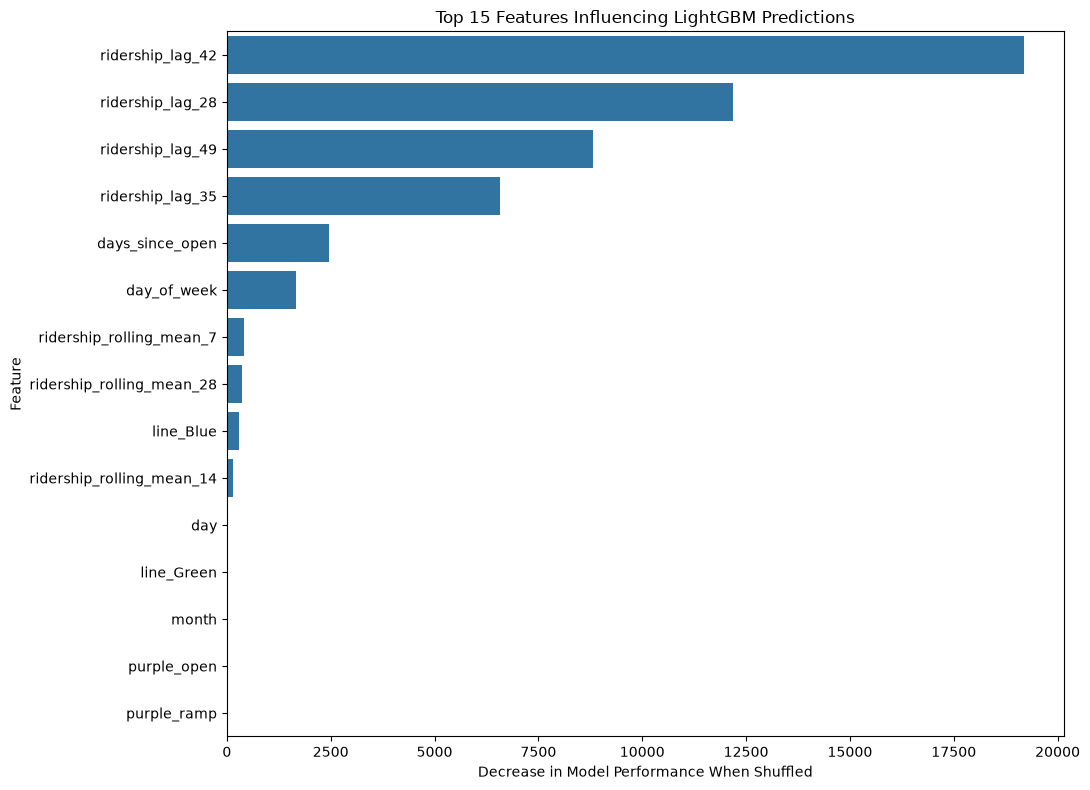

In [170]:
plt.figure(figsize=(11, 8))

sns.barplot(
    data=importance_df.head(15),
    x='Importance',
    y='Feature'
)

plt.title('Top 15 Features Influencing LightGBM Predictions')
plt.xlabel('Decrease in Model Performance When Shuffled')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

In [171]:
error_analysis = backtest_predictions[
    backtest_predictions['model'] == 'LightGBM'
].copy()

error_analysis['error'] = (
    error_analysis['actual'] -
    error_analysis['predicted']
)

error_analysis['absolute_error'] = (
    error_analysis['error'].abs()
)

error_analysis['percentage_error'] = (
    error_analysis['error'] /
    error_analysis['actual']
) * 100

display(error_analysis.head())

,date,line,actual,predicted,model,window,error,absolute_error,percentage_error
168,2024-12-04,Blue,193071.0,185244.759321,LightGBM,1,7826.240679,7826.240679,4.053556
169,2024-12-04,Green,167155.0,171728.782567,LightGBM,1,-4573.782567,4573.782567,-2.736252
170,2024-12-04,Purple,92205.0,89488.099507,LightGBM,1,2716.900493,2716.900493,2.946587
171,2024-12-05,Blue,208836.0,199028.387617,LightGBM,1,9807.612383,9807.612383,4.696323
172,2024-12-05,Green,173011.0,175245.589626,LightGBM,1,-2234.589626,2234.589626,-1.291588


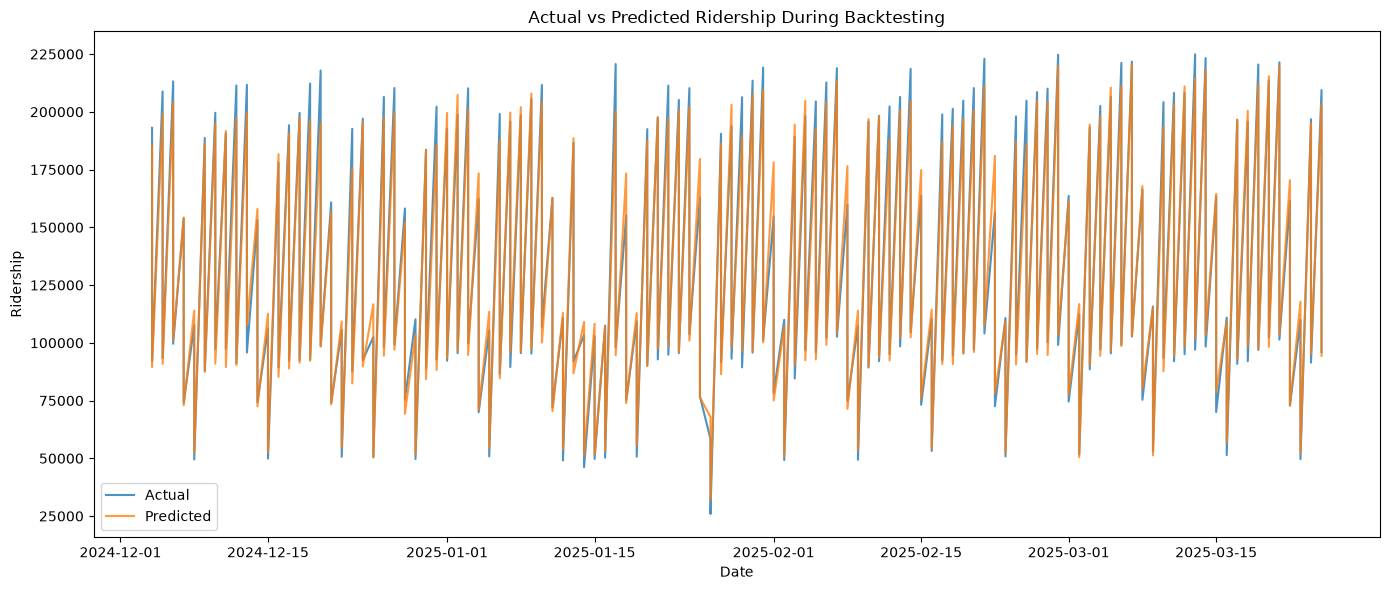

In [172]:
plt.figure(figsize=(14, 6))

plt.plot(
    error_analysis['date'],
    error_analysis['actual'],
    label='Actual',
    alpha=0.8
)

plt.plot(
    error_analysis['date'],
    error_analysis['predicted'],
    label='Predicted',
    alpha=0.8
)

plt.title('Actual vs Predicted Ridership During Backtesting')
plt.xlabel('Date')
plt.ylabel('Ridership')
plt.legend()
plt.tight_layout()
plt.show()

In [173]:
daily_rainfall = (
    df_clean.groupby('date')['rainfall_mm']
    .mean()
    .reset_index()
)

error_analysis = error_analysis.merge(
    daily_rainfall,
    on='date',
    how='left'
)

display(
    error_analysis[
        ['date', 'actual', 'predicted', 'error', 'rainfall_mm']
    ].head()
)

,date,actual,predicted,error,rainfall_mm
0,2024-12-04,193071.0,185244.759321,7826.240679,0.9
1,2024-12-04,167155.0,171728.782567,-4573.782567,0.9
2,2024-12-04,92205.0,89488.099507,2716.900493,0.9
3,2024-12-05,208836.0,199028.387617,9807.612383,1.0
4,2024-12-05,173011.0,175245.589626,-2234.589626,1.0


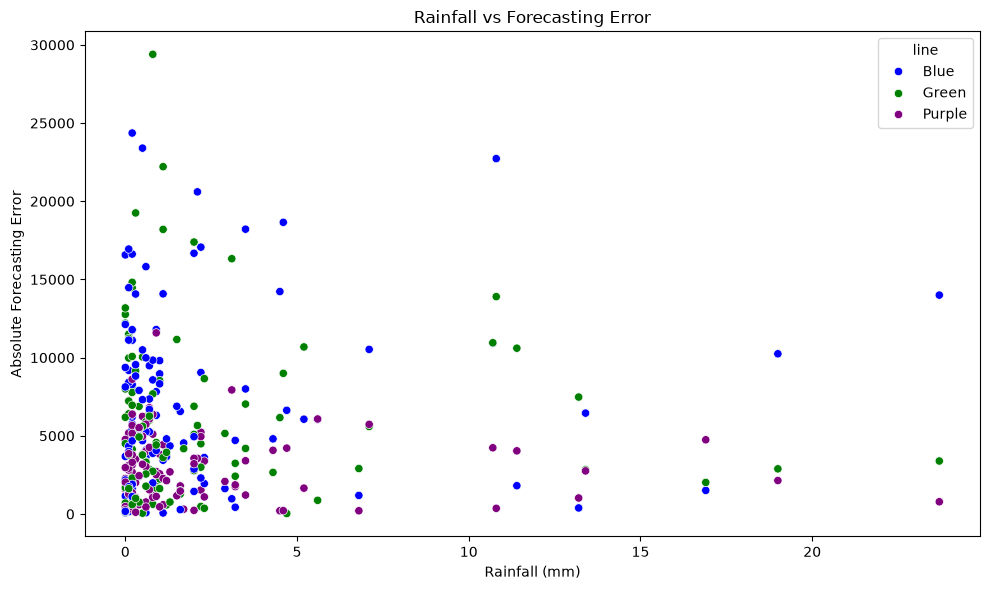

In [174]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=error_analysis,
    x='rainfall_mm',
    y='absolute_error',
    hue='line',
    palette=line_colors
)

plt.title('Rainfall vs Forecasting Error')
plt.xlabel('Rainfall (mm)')
plt.ylabel('Absolute Forecasting Error')
plt.tight_layout()
plt.show()

In [175]:
line_error_summary = (
    error_analysis.groupby('line')
    .agg(
        MAE=('absolute_error', 'mean'),
        Average_Error=('error', 'mean'),
        Maximum_Error=('absolute_error', 'max')
    )
    .reset_index()
)

display(line_error_summary.round(2))

,line,MAE,Average_Error,Maximum_Error
0,Blue,7264.46,1995.22,24363.66
1,Green,5734.59,-1702.53,29398.47
2,Purple,3017.26,-210.19,11583.54


#  Metro Capacity Planning 

In [176]:
peak_hour_share = 0.10
peak_direction_share = 0.60
train_capacity = 1200

In [177]:
capacity_data = forecast_data.copy()

capacity_data['PHPDT'] = (
    capacity_data['predicted_ridership']
    * peak_hour_share
    * peak_direction_share
)

display(capacity_data.head())

,date,line,predicted_ridership,PHPDT
0,2025-07-01,Blue,196679.616376,11800.776983
1,2025-07-02,Blue,198868.828160,11932.129690
2,2025-07-03,Blue,205131.191842,12307.871511
3,2025-07-04,Blue,219206.392572,13152.383554
4,2025-07-05,Blue,162700.460797,9762.027648


In [178]:
capacity_data['required_trains_per_hour'] = np.ceil(
    capacity_data['PHPDT'] / train_capacity
).astype(int)

display(
    capacity_data[
        ['date', 'line', 'PHPDT', 'required_trains_per_hour']
    ].head()
)

,date,line,PHPDT,required_trains_per_hour
0,2025-07-01,Blue,11800.776983,10
1,2025-07-02,Blue,11932.129690,10
2,2025-07-03,Blue,12307.871511,11
3,2025-07-04,Blue,13152.383554,11
4,2025-07-05,Blue,9762.027648,9


In [179]:
capacity_data['required_headway_minutes'] = (
    60 / capacity_data['required_trains_per_hour']
)

display(
    capacity_data[
        [
            'date',
            'line',
            'PHPDT',
            'required_trains_per_hour',
            'required_headway_minutes'
        ]
    ].head()
)

,date,line,PHPDT,required_trains_per_hour,required_headway_minutes
0,2025-07-01,Blue,11800.776983,10,6.000000
1,2025-07-02,Blue,11932.129690,10,6.000000
2,2025-07-03,Blue,12307.871511,11,5.454545
3,2025-07-04,Blue,13152.383554,11,5.454545
4,2025-07-05,Blue,9762.027648,9,6.666667


In [180]:
capacity_summary = (
    capacity_data.groupby('line')
    .agg(
        average_daily_ridership=('predicted_ridership', 'mean'),
        maximum_daily_ridership=('predicted_ridership', 'max'),
        maximum_PHPDT=('PHPDT', 'max'),
        average_PHPDT=('PHPDT', 'mean'),
        required_trains_per_hour=('required_trains_per_hour', 'max'),
        required_headway_minutes=('required_headway_minutes', 'min')
    )
    .reset_index()
)

display(capacity_summary.round(2))

,line,average_daily_ridership,maximum_daily_ridership,maximum_PHPDT,average_PHPDT,required_trains_per_hour,required_headway_minutes
0,Blue,184620.09,219206.39,13152.38,11077.21,11,5.45
1,Green,159604.43,191897.86,11513.87,9576.27,10,6.00
2,Purple,85693.91,99848.85,5990.93,5141.63,5,12.00


In [181]:
existing_frequency = {
    'Blue': 14,
    'Green': 10,
    'Purple': 7
}

capacity_summary['existing_trains_per_hour'] = (
    capacity_summary['line'].map(existing_frequency)
)

capacity_summary['frequency_difference'] = (
    capacity_summary['required_trains_per_hour']
    - capacity_summary['existing_trains_per_hour']
)

capacity_summary['capacity_status'] = np.where(
    capacity_summary['frequency_difference'] > 0,
    'Additional trains required',
    'Existing frequency sufficient'
)

display(capacity_summary.round(2))

,line,average_daily_ridership,maximum_daily_ridership,maximum_PHPDT,average_PHPDT,required_trains_per_hour,required_headway_minutes,existing_trains_per_hour,frequency_difference,capacity_status
0,Blue,184620.09,219206.39,13152.38,11077.21,11,5.45,14,-3,Existing frequency sufficient
1,Green,159604.43,191897.86,11513.87,9576.27,10,6.00,10,0,Existing frequency sufficient
2,Purple,85693.91,99848.85,5990.93,5141.63,5,12.00,7,-2,Existing frequency sufficient


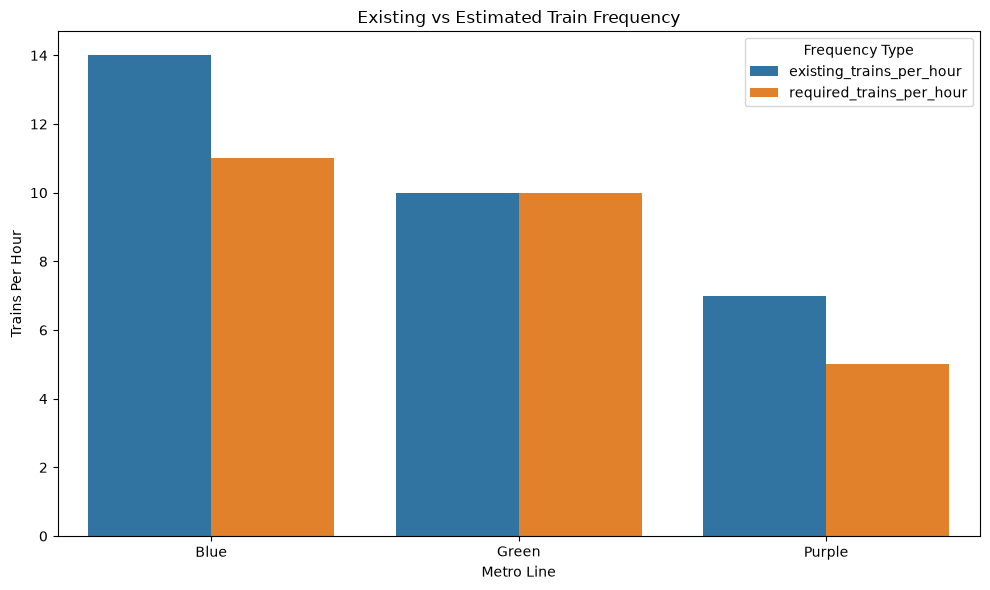

In [182]:
plt.figure(figsize=(10, 6))

comparison_data = capacity_summary.melt(
    id_vars='line',
    value_vars=[
        'existing_trains_per_hour',
        'required_trains_per_hour'
    ],
    var_name='Frequency Type',
    value_name='Trains Per Hour'
)

sns.barplot(
    data=comparison_data,
    x='line',
    y='Trains Per Hour',
    hue='Frequency Type'
)

plt.title('Existing vs Estimated Train Frequency')
plt.xlabel('Metro Line')
plt.ylabel('Trains Per Hour')
plt.tight_layout()
plt.show()

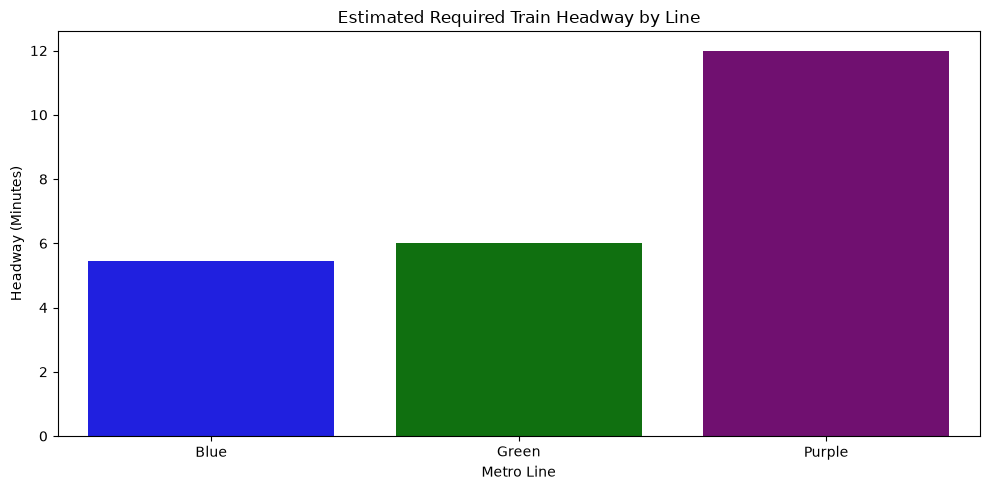

In [183]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=capacity_summary,
    x='line',
    y='required_headway_minutes',
    hue='line',
    palette=line_colors,
    legend=False
)

plt.title('Estimated Required Train Headway by Line')
plt.xlabel('Metro Line')
plt.ylabel('Headway (Minutes)')
plt.tight_layout()
plt.show()

# Model Saving and Project Deliverables

In [185]:
import os
import json
import joblib
from pathlib import Path

project_path = Path.cwd().parent

models_path = project_path / 'models'
outputs_path = project_path / 'outputs'
charts_path = outputs_path / 'charts'

models_path.mkdir(parents=True, exist_ok=True)
outputs_path.mkdir(parents=True, exist_ok=True)
charts_path.mkdir(parents=True, exist_ok=True)

print("Project directories ready.")

Project directories ready.


In [186]:
model_bundle = {
    'model': final_lgbm_model,
    'feature_columns': lgbm_feature_columns,
    'parameters': best_parameters,
    'target': 'ridership'
}

joblib.dump(
    model_bundle,
    models_path / 'metro_ridership_lightgbm.pkl'
)

print("LightGBM model saved successfully.")

LightGBM model saved successfully.


In [187]:
final_metrics_df.to_csv(
    outputs_path / 'final_metrics.csv',
    index=False
)

tuning_df.to_csv(
    outputs_path / 'lightgbm_tuning_results.csv',
    index=False
)

print("Evaluation metrics saved.")

Evaluation metrics saved.


In [188]:
backtest_predictions.to_csv(
    outputs_path / 'backtest_predictions.csv',
    index=False
)

print("Backtesting results saved.")

Backtesting results saved.


In [189]:
forecast_data.to_csv(
    outputs_path / 'line_level_forecast.csv',
    index=False
)

network_forecast.to_csv(
    outputs_path / 'network_forecast.csv',
    index=False
)

print("Forecast results saved.")

Forecast results saved.


In [190]:
capacity_data.to_csv(
    outputs_path / 'daily_capacity_planning.csv',
    index=False
)

capacity_summary.to_csv(
    outputs_path / 'capacity_summary.csv',
    index=False
)

print("Capacity-planning results saved.")

Capacity-planning results saved.


In [191]:
importance_df.to_csv(
    outputs_path / 'feature_importance.csv',
    index=False
)

line_error_summary.to_csv(
    outputs_path / 'line_error_summary.csv',
    index=False
)

error_analysis.to_csv(
    outputs_path / 'forecast_error_analysis.csv',
    index=False
)

print("Explainability results saved.")

Explainability results saved.


In [192]:
best_model_row = final_metrics_df.iloc[0]

project_summary = {
    'project_name': 'Metro Rail Ridership Forecasting',

    'project_id': 'terv-aiml-tftpl434-metro-ridership-forecast',

    'objective': 'Forecast daily metro ridership 28 days ahead.',

    'dataset': {
        'records': int(len(df_clean)),
        'columns': int(len(df_clean.columns)),
        'start_date': str(df_clean['date'].min().date()),
        'end_date': str(df_clean['date'].max().date()),
        'lines': ['Blue', 'Green', 'Purple'],
        'data_type': 'Synthetic demonstration dataset'
    },

    'best_model': str(best_model_row['Model']),

    'final_metrics': {
        'MAE': float(best_model_row['MAE']),
        'RMSE': float(best_model_row['RMSE']),
        'MAPE': float(best_model_row['MAPE'])
    },

    'best_parameters': {
        key: (
            int(value) if key in [
                'n_estimators',
                'max_depth',
                'num_leaves'
            ] else float(value)
        )
        for key, value in best_parameters.items()
    },

    'forecast_period': {
        'start': '2025-07-01',
        'end': '2025-07-28'
    },

    'capacity_planning': capacity_summary.to_dict(
        orient='records'
    )
}

with open(
    outputs_path / 'summary.json',
    'w',
    encoding='utf-8'
) as file:

    json.dump(
        project_summary,
        file,
        indent=4,
        default=str
    )

print("Project summary saved.")

Project summary saved.


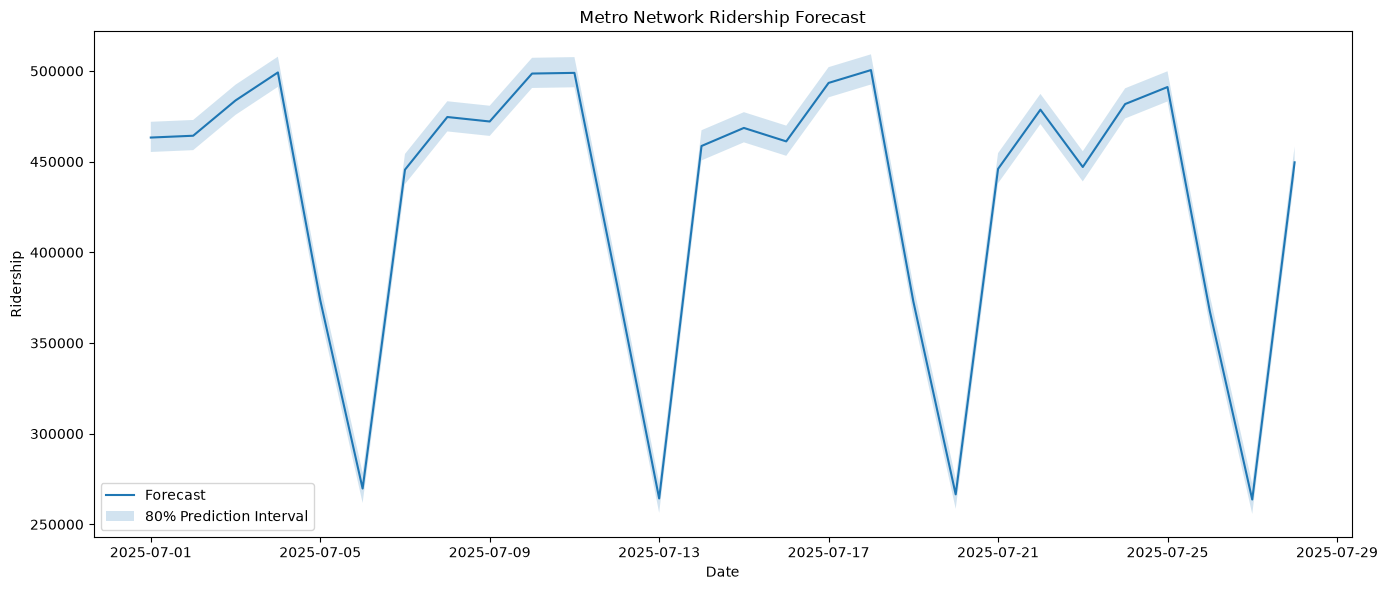

In [193]:
plt.figure(figsize=(14, 6))

plt.plot(
    network_forecast['date'],
    network_forecast['network_ridership'],
    label='Forecast'
)

plt.fill_between(
    network_forecast['date'],
    network_forecast['lower_80'],
    network_forecast['upper_80'],
    alpha=0.2,
    label='80% Prediction Interval'
)

plt.title('Metro Network Ridership Forecast')
plt.xlabel('Date')
plt.ylabel('Ridership')
plt.legend()
plt.tight_layout()

plt.savefig(
    charts_path / 'network_forecast.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

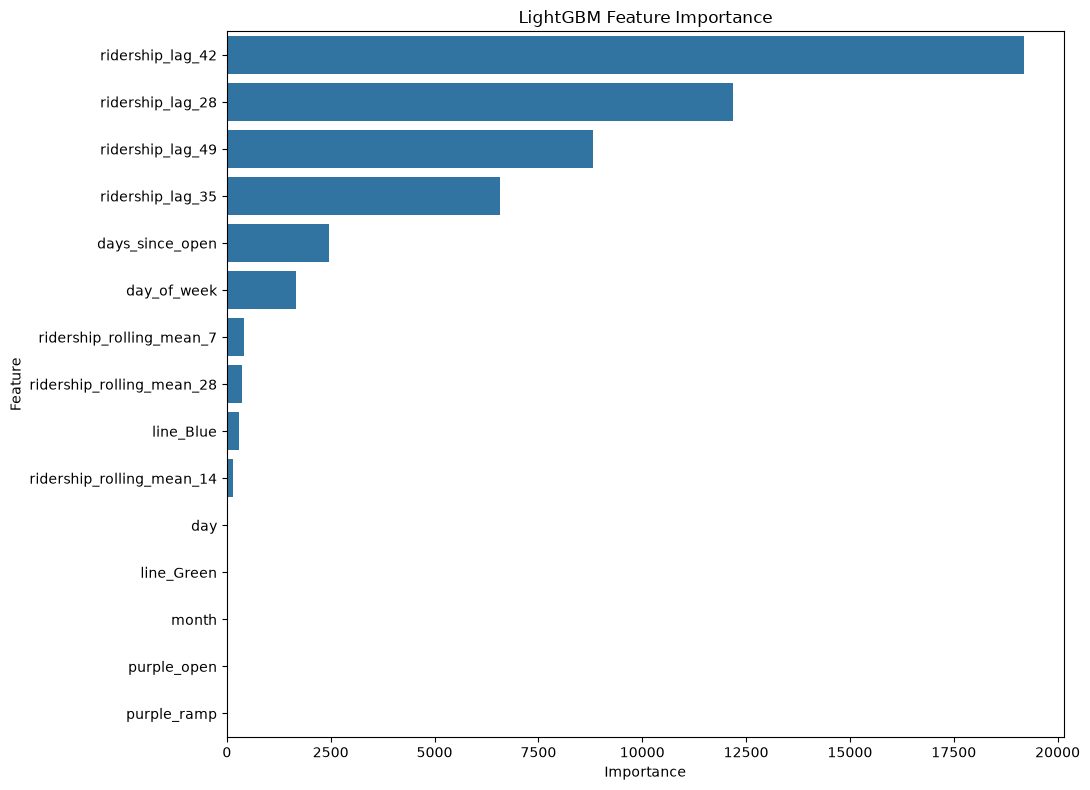

In [194]:
plt.figure(figsize=(11, 8))

sns.barplot(
    data=importance_df.head(15),
    x='Importance',
    y='Feature'
)

plt.title('LightGBM Feature Importance')
plt.tight_layout()

plt.savefig(
    charts_path / 'feature_importance.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

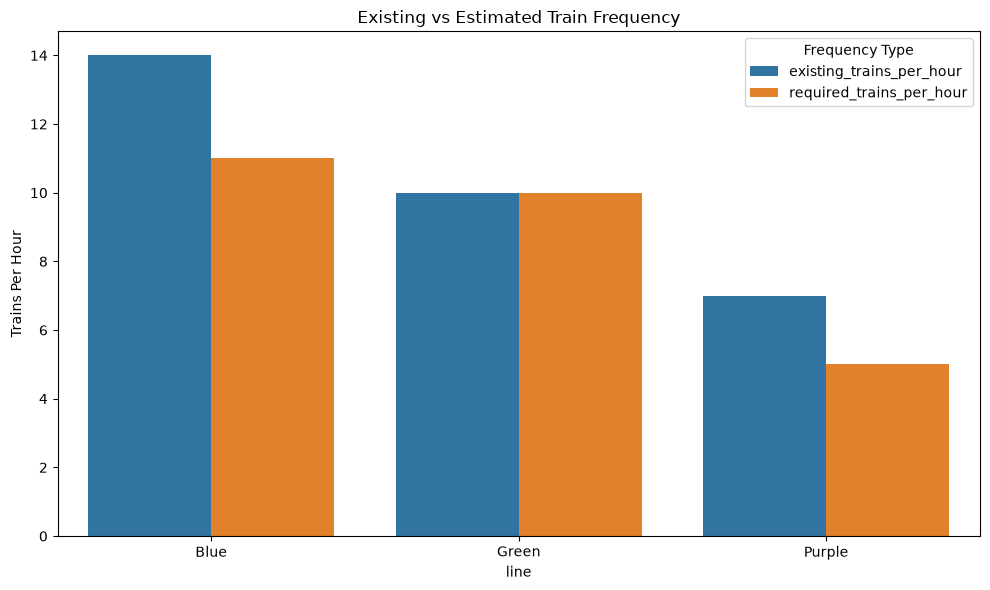

In [195]:
plt.figure(figsize=(10, 6))

comparison_data = capacity_summary.melt(
    id_vars='line',
    value_vars=[
        'existing_trains_per_hour',
        'required_trains_per_hour'
    ],
    var_name='Frequency Type',
    value_name='Trains Per Hour'
)

sns.barplot(
    data=comparison_data,
    x='line',
    y='Trains Per Hour',
    hue='Frequency Type'
)

plt.title('Existing vs Estimated Train Frequency')
plt.tight_layout()

plt.savefig(
    charts_path / 'capacity_comparison.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [196]:
for folder in [models_path, outputs_path, charts_path]:

    print(f"\n{folder.name.upper()}")

    for file in sorted(folder.iterdir()):
        if file.is_file():
            print(" -", file.name)


MODELS
 - metro_ridership_lightgbm.pkl

OUTPUTS
 - backtest_predictions.csv
 - capacity_summary.csv
 - daily_capacity_planning.csv
 - feature_importance.csv
 - final_metrics.csv
 - forecast_error_analysis.csv
 - lightgbm_tuning_results.csv
 - line_error_summary.csv
 - line_level_forecast.csv
 - network_forecast.csv
 - summary.json

CHARTS
 - capacity_comparison.png
 - feature_importance.png
 - network_forecast.png


In [199]:
from pathlib import Path

project_path = Path.cwd()

cleaned_data_path = project_path / "outputs" / "cleaned_metro_ridership.csv"

df_clean.to_csv(cleaned_data_path, index=False)

print("Cleaned dataset saved successfully!")
print("Location:", cleaned_data_path)
print("Shape:", df_clean.shape)

Cleaned dataset saved successfully!
Location: C:\Users\santhosh\Documents\PROJECT_METRO\outputs\cleaned_metro_ridership.csv
Shape: (2669, 8)


In [205]:
from pathlib import Path

project_path = Path.cwd()

required_files = [
    "app/Home.py",
    "app/utils.py",
    "app/pages/1_Ridership_Analysis.py",
    "app/pages/2_Line_Analysis.py",
    "app/pages/3_Forecasting.py",
    "app/pages/4_Model_Performance.py",
    "app/pages/5_Explainability.py",
    "app/pages/6_Capacity_Planning.py",
    "outputs/cleaned_metro_ridership.csv",
    "outputs/final_metrics.csv",
    "outputs/network_forecast.csv",
    "outputs/line_level_forecast.csv",
    "outputs/daily_capacity_planning.csv",
    "outputs/capacity_summary.csv",
    "models/metro_ridership_lightgbm.pkl"
]

for file in required_files:
    status = "FOUND" if (project_path / file).exists() else "MISSING"
    print(f"{status}: {file}")

FOUND: app/Home.py
FOUND: app/utils.py
FOUND: app/pages/1_Ridership_Analysis.py
FOUND: app/pages/2_Line_Analysis.py
FOUND: app/pages/3_Forecasting.py
FOUND: app/pages/4_Model_Performance.py
FOUND: app/pages/5_Explainability.py
FOUND: app/pages/6_Capacity_Planning.py
FOUND: outputs/cleaned_metro_ridership.csv
FOUND: outputs/final_metrics.csv
FOUND: outputs/network_forecast.csv
FOUND: outputs/line_level_forecast.csv
FOUND: outputs/daily_capacity_planning.csv
FOUND: outputs/capacity_summary.csv
FOUND: models/metro_ridership_lightgbm.pkl


In [15]:
from pathlib import Path
import shutil
import ast

file_path = Path(
    r"C:\Users\santhosh\Documents\PROJECT_METRO\app\components.py"
)

# Create backup
backup_path = file_path.with_suffix(".repair.backup")
shutil.copy2(file_path, backup_path)

lines = file_path.read_text(encoding="utf-8").splitlines()

# --------------------------------------------------
# 1. FIX show_chart FUNCTION PARAMETER
# --------------------------------------------------

for i, line in enumerate(lines):

    if 'width="stretch",' in line and i < 400:

        lines[i] = "    use_container_width=True,"
        break

# --------------------------------------------------
# 2. FIX PLOTLY CHART CALL AND INDENTATION
# --------------------------------------------------

chart_start = None

for i, line in enumerate(lines):

    if "st.plotly_chart(" in line:

        chart_start = i
        break

if chart_start is None:
    raise ValueError("Could not find st.plotly_chart()")

chart_end = None

for i in range(chart_start, len(lines)):

    if lines[i].strip() == ")":

        chart_end = i
        break

if chart_end is None:
    raise ValueError("Could not find the end of st.plotly_chart()")

correct_chart = [
    "    st.plotly_chart(",
    "        figure,",
    '        width="stretch" if use_container_width else "content",',
    "        key=key,",
    "        config={",
    '            "displayModeBar": False,',
    '            "displaylogo": False,',
    '            "responsive": True,',
    "        },",
    "    )",
]

lines[chart_start:chart_end + 1] = correct_chart

# --------------------------------------------------
# 3. RESTORE show_dataframe FUNCTION
# --------------------------------------------------

dataframe_start = None
empty_state_start = None

for i, line in enumerate(lines):

    if "# 7. DATAFRAME" in line:
        dataframe_start = i

    if "# 8. EMPTY STATE" in line:
        empty_state_start = i
        break

if dataframe_start is None or empty_state_start is None:
    raise ValueError("Could not locate dataframe section boundaries.")

correct_dataframe = [
    "# ============================================================",
    "# 7. DATAFRAME",
    "# ============================================================",
    "",
    "def show_dataframe(dataframe, height=400, hide_index=True):",
    "",
    "    if dataframe is None or dataframe.empty:",
    '        st.info("No records available.")',
    "        return",
    "",
    "    st.dataframe(",
    "        dataframe,",
    '        width="stretch",',
    "        height=height,",
    "        hide_index=hide_index,",
    "    )",
    "",
    "",
]

lines[dataframe_start:empty_state_start] = (
    correct_dataframe + lines[empty_state_start:]
)

# --------------------------------------------------
# 4. SAVE FILE
# --------------------------------------------------

updated_code = "\n".join(lines) + "\n"

# Check syntax BEFORE saving
ast.parse(updated_code)

file_path.write_text(updated_code, encoding="utf-8")

print("SUCCESS: components.py repaired.")
print("Chart function: Corrected")
print("Dataframe function: Restored")
print("Plotly width: Updated")
print("Indentation: Valid")
print("Python syntax: Valid")
print("Backup:", backup_path)

SUCCESS: components.py repaired.
Chart function: Corrected
Dataframe function: Restored
Plotly width: Updated
Indentation: Valid
Python syntax: Valid
Backup: C:\Users\santhosh\Documents\PROJECT_METRO\app\components.repair.backup


In [17]:
from pathlib import Path

file_path = Path(
    r"C:\Users\santhosh\Documents\PROJECT_METRO\app\components.py"
)

code = file_path.read_text(encoding="utf-8")

# Remove Markdown code fences if present
lines = code.splitlines()

if lines and lines[0].strip().startswith("```"):
    lines = lines[1:]

if lines and lines[-1].strip() == "```":
    lines = lines[:-1]

code = "\n".join(lines)

file_path.write_text(code, encoding="utf-8")

print("Markdown code fences removed.")
print("First line:", repr(code.splitlines()[0]))

Markdown code fences removed.
First line: 'from pathlib import Path'


In [18]:
import ast

code = file_path.read_text(encoding="utf-8")

ast.parse(code)

print("SUCCESS: components.py syntax is valid.")

SUCCESS: components.py syntax is valid.


In [20]:
import ast
from pathlib import Path

file_path = Path(
    r"C:\Users\santhosh\Documents\PROJECT_METRO\app\pages\1_Ridership_Analysis.py"
)

code = file_path.read_text(encoding="utf-8")

ast.parse(code)

print("Ridership Analysis: SYNTAX VALID")
print("File size:", round(file_path.stat().st_size / 1024, 2), "KB")

Ridership Analysis: SYNTAX VALID
File size: 21.65 KB


In [23]:
import pandas as pd
from pathlib import Path

# ----------------------------------------
# PROJECT PATH
# ----------------------------------------

PROJECT_PATH = Path(
    r"C:\Users\santhosh\Documents\PROJECT_METRO"
)

OUTPUT_PATH = PROJECT_PATH / "outputs"

CLEAN_PATH = OUTPUT_PATH / "cleaned_metro_ridership.csv"


# ----------------------------------------
# LOAD CLEANED DATASET
# ----------------------------------------

clean_df = pd.read_csv(CLEAN_PATH)

clean_df["date"] = pd.to_datetime(
    clean_df["date"],
    errors="coerce"
)


# ----------------------------------------
# DATASET OVERVIEW
# ----------------------------------------

print("=" * 60)
print("METRO RIDERSHIP DATA VALIDATION")
print("=" * 60)

print("\nDATASET DIMENSIONS")
print("Rows:", clean_df.shape[0])
print("Columns:", clean_df.shape[1])

print("\nCOLUMN NAMES")
print(clean_df.columns.tolist())

print("\nDATE RANGE")
print("Start:", clean_df["date"].min())
print("End:", clean_df["date"].max())


# ----------------------------------------
# MISSING VALUE CHECK
# ----------------------------------------

print("\nMISSING VALUES")

print(clean_df.isnull().sum())

print(
    "\nTotal Missing Values:",
    clean_df.isnull().sum().sum()
)


# ----------------------------------------
# DUPLICATE CHECK
# ----------------------------------------

print("\nDUPLICATE CHECK")

print(
    "Exact Duplicate Rows:",
    clean_df.duplicated().sum()
)

print(
    "Duplicate Date-Line Combinations:",
    clean_df.duplicated(
        subset=["date", "line"]
    ).sum()
)


# ----------------------------------------
# LINE DISTRIBUTION
# ----------------------------------------

print("\nLINE-WISE RECORD COUNTS")

print(clean_df["line"].value_counts())


# ----------------------------------------
# RIDERSHIP VALIDATION
# ----------------------------------------

print("\nRIDERSHIP STATISTICS")

print(
    clean_df["ridership"].describe()
)

print(
    "\nZero Ridership Records:",
    (clean_df["ridership"] == 0).sum()
)

print(
    "Negative Ridership Records:",
    (clean_df["ridership"] < 0).sum()
)


# ----------------------------------------
# DATE AND LINE COVERAGE
# ----------------------------------------

print("\nDATE AND LINE COVERAGE")

print("Unique Dates:", clean_df["date"].nunique())

print("Unique Lines:", clean_df["line"].nunique())

print(
    clean_df.groupby("line")["date"]
    .agg(["min", "max", "count"])
)


# ----------------------------------------
# ML OUTPUT FILE CHECK
# ----------------------------------------

print("\nML OUTPUT FILE VALIDATION")

expected_files = [
    "backtest_predictions.csv",
    "capacity_summary.csv",
    "cleaned_metro_ridership.csv",
    "daily_capacity_planning.csv",
    "feature_importance.csv",
    "final_metrics.csv",
    "forecast_error_analysis.csv",
    "lightgbm_tuning_results.csv",
    "line_error_summary.csv",
    "line_level_forecast.csv",
    "network_forecast.csv"
]

for filename in expected_files:

    file_path = OUTPUT_PATH / filename

    if file_path.exists():
        print("AVAILABLE:", filename)
    else:
        print("MISSING:", filename)


# ----------------------------------------
# FINAL SUMMARY
# ----------------------------------------

print("\n" + "=" * 60)
print("DATA VALIDATION COMPLETED")
print("=" * 60)

METRO RIDERSHIP DATA VALIDATION

DATASET DIMENSIONS
Rows: 2669
Columns: 8

COLUMN NAMES
['date', 'line', 'ridership', 'trains_operated', 'rainfall_mm', 'holiday', 'special_event', 'day_name']

DATE RANGE
Start: 2022-07-01 00:00:00
End: 2025-06-30 00:00:00

MISSING VALUES
date               0
line               0
ridership          0
trains_operated    0
rainfall_mm        0
holiday            0
special_event      0
day_name           0
dtype: int64

Total Missing Values: 0

DUPLICATE CHECK
Exact Duplicate Rows: 0
Duplicate Date-Line Combinations: 0

LINE-WISE RECORD COUNTS
line
Blue      1096
Green     1096
Purple     477
Name: count, dtype: int64

RIDERSHIP STATISTICS
count      2669.000000
mean     127372.180405
std       44871.153239
min        6508.000000
25%       93747.000000
50%      129210.000000
75%      160438.000000
max      237676.000000
Name: ridership, dtype: float64

Zero Ridership Records: 0
Negative Ridership Records: 0

DATE AND LINE COVERAGE
Unique Dates: 1096
Unique

In [24]:
import pandas as pd
from pathlib import Path

PROJECT_PATH = Path(
    r"C:\Users\santhosh\Documents\PROJECT_METRO"
)

OUTPUT_PATH = PROJECT_PATH / "outputs"

# Load model metrics
metrics = pd.read_csv(
    OUTPUT_PATH / "final_metrics.csv"
)

print("=" * 60)
print("MODEL PERFORMANCE VALIDATION")
print("=" * 60)

print("\nCOLUMNS:")
print(metrics.columns.tolist())

print("\nMODEL METRICS:")
display(metrics)

print("\nDATASET INFORMATION:")
print("Number of models:", len(metrics))
print("Missing values:", metrics.isnull().sum().sum())
print("Duplicate rows:", metrics.duplicated().sum())

MODEL PERFORMANCE VALIDATION

COLUMNS:
['Model', 'MAE', 'RMSE', 'MAPE']

MODEL METRICS:


,Model,MAE,RMSE,MAPE
0,SARIMAX,10333.287804,20004.864980,2.496333
1,LightGBM,13477.225641,21268.514514,3.337315
2,Seasonal Naive,26223.619048,59703.639872,6.758841



DATASET INFORMATION:
Number of models: 3
Missing values: 0
Duplicate rows: 0


In [25]:
backtest = pd.read_csv(
    OUTPUT_PATH / "backtest_predictions.csv"
)

print("=" * 60)
print("BACKTESTING VALIDATION")
print("=" * 60)

print("\nShape:", backtest.shape)

print("\nColumns:")
print(backtest.columns.tolist())

print("\nMissing Values:")
print(backtest.isnull().sum())

print("\nFirst 10 Records:")
display(backtest.head(10))

print("\nLast 10 Records:")
display(backtest.tail(10))

BACKTESTING VALIDATION

Shape: (1008, 6)

Columns:
['date', 'line', 'actual', 'predicted', 'model', 'window']

Missing Values:
date         0
line         0
actual       0
predicted    0
model        0
window       0
dtype: int64

First 10 Records:


,date,line,actual,predicted,model,window
0,2024-12-04,Blue,193071.0,188725.0,Seasonal Naive,1
1,2024-12-04,Green,167155.0,163686.0,Seasonal Naive,1
2,2024-12-04,Purple,92205.0,90195.0,Seasonal Naive,1
3,2024-12-05,Blue,208836.0,204747.0,Seasonal Naive,1
4,2024-12-05,Green,173011.0,168426.0,Seasonal Naive,1
5,2024-12-05,Purple,93431.0,94999.0,Seasonal Naive,1
6,2024-12-06,Blue,213170.0,199406.0,Seasonal Naive,1
7,2024-12-06,Green,179224.0,184641.0,Seasonal Naive,1
8,2024-12-06,Purple,99581.0,104745.0,Seasonal Naive,1
9,2024-12-07,Blue,153871.0,151904.0,Seasonal Naive,1



Last 10 Records:


,date,line,actual,predicted,model,window
998,2025-03-22,Purple,72847.0,72735.578791,LightGBM,4
999,2025-03-23,Blue,109902.0,117805.904956,LightGBM,4
1000,2025-03-23,Green,97934.0,102860.958290,LightGBM,4
1001,2025-03-23,Purple,49648.0,52098.953648,LightGBM,4
1002,2025-03-24,Blue,196805.0,195063.550494,LightGBM,4
1003,2025-03-24,Green,168682.0,170307.349218,LightGBM,4
1004,2025-03-24,Purple,91389.0,95242.910724,LightGBM,4
1005,2025-03-25,Blue,209429.0,203365.817810,LightGBM,4
1006,2025-03-25,Green,168921.0,179604.772145,LightGBM,4
1007,2025-03-25,Purple,96013.0,94359.061424,LightGBM,4


In [26]:
import pandas as pd
from pathlib import Path

PROJECT_PATH = Path(
    r"C:\Users\santhosh\Documents\PROJECT_METRO"
)

OUTPUT_PATH = PROJECT_PATH / "outputs"

# ----------------------------------------
# NETWORK FORECAST
# ----------------------------------------

network_forecast = pd.read_csv(
    OUTPUT_PATH / "network_forecast.csv"
)

print("=" * 60)
print("NETWORK FORECAST VALIDATION")
print("=" * 60)

print("\nShape:", network_forecast.shape)

print("\nColumns:")
print(network_forecast.columns.tolist())

print("\nMissing Values:")
print(network_forecast.isnull().sum())

print("\nForecast Records:")
display(network_forecast.head(10))

print("\nForecast Summary:")
display(network_forecast.describe())


# ----------------------------------------
# LINE LEVEL FORECAST
# ----------------------------------------

line_forecast = pd.read_csv(
    OUTPUT_PATH / "line_level_forecast.csv"
)

print("\n" + "=" * 60)
print("LINE LEVEL FORECAST VALIDATION")
print("=" * 60)

print("\nShape:", line_forecast.shape)

print("\nColumns:")
print(line_forecast.columns.tolist())

print("\nMissing Values:")
print(line_forecast.isnull().sum())

print("\nForecast Records:")
display(line_forecast.head(10))

print("\nLine Distribution:")
print(line_forecast["line"].value_counts())

NETWORK FORECAST VALIDATION

Shape: (28, 4)

Columns:
['date', 'network_ridership', 'lower_80', 'upper_80']

Missing Values:
date                 0
network_ridership    0
lower_80             0
upper_80             0
dtype: int64

Forecast Records:


,date,network_ridership,lower_80,upper_80
0,2025-07-01,463281.544162,455330.310318,471973.051696
1,2025-07-02,464284.677935,456333.444091,472976.185470
2,2025-07-03,483736.267988,475785.034143,492427.775522
3,2025-07-04,499176.173318,491224.939474,507867.680853
4,2025-07-05,373584.045656,365632.811811,382275.553190
5,2025-07-06,269734.323237,261783.089392,278425.830771
6,2025-07-07,445563.928535,437612.694691,454255.436070
7,2025-07-08,474608.616482,466657.382638,483300.124016
8,2025-07-09,472131.115752,464179.881908,480822.623286
9,2025-07-10,498573.618436,490622.384592,507265.125970



Forecast Summary:


,network_ridership,lower_80,upper_80
count,28.000000,28.000000,28.000000
mean,429918.423418,421967.189574,438609.930953
std,78298.671832,78298.671832,78298.671832
min,263679.798952,255728.565108,272371.306486
25%,380547.673696,372596.439852,389239.181230
50%,462223.829313,454272.595469,470915.336847
75%,482248.672655,474297.438810,490940.180189
max,500485.306610,492534.072765,509176.814144



LINE LEVEL FORECAST VALIDATION

Shape: (84, 3)

Columns:
['date', 'line', 'predicted_ridership']

Missing Values:
date                   0
line                   0
predicted_ridership    0
dtype: int64

Forecast Records:


,date,line,predicted_ridership
0,2025-07-01,Blue,196679.616376
1,2025-07-02,Blue,198868.828160
2,2025-07-03,Blue,205131.191842
3,2025-07-04,Blue,219206.392572
4,2025-07-05,Blue,162700.460797
5,2025-07-06,Blue,115461.277590
6,2025-07-07,Blue,189988.299147
7,2025-07-08,Blue,203058.581515
8,2025-07-09,Blue,200179.455080
9,2025-07-10,Blue,213696.312204



Line Distribution:
line
Blue      28
Green     28
Purple    28
Name: count, dtype: int64


In [27]:
# Convert dates
network_forecast["date"] = pd.to_datetime(
    network_forecast["date"]
)

line_forecast["date"] = pd.to_datetime(
    line_forecast["date"]
)

# Aggregate line-level predictions
daily_line_total = (
    line_forecast
    .groupby("date")["predicted_ridership"]
    .sum()
    .reset_index(name="line_total")
)

# Compare with network forecast
comparison = network_forecast.merge(
    daily_line_total,
    on="date",
    how="inner"
)

comparison["difference"] = (
    comparison["network_ridership"]
    - comparison["line_total"]
)

print("NETWORK VS LINE FORECAST CONSISTENCY")

display(comparison.head(10))

print("\nMaximum absolute difference:")
print(comparison["difference"].abs().max())

print("\nMean absolute difference:")
print(comparison["difference"].abs().mean())

NETWORK VS LINE FORECAST CONSISTENCY


,date,network_ridership,lower_80,upper_80,line_total,difference
0,2025-07-01,463281.544162,455330.310318,471973.051696,463281.544162,5.820766e-11
1,2025-07-02,464284.677935,456333.444091,472976.185470,464284.677935,0.000000e+00
2,2025-07-03,483736.267988,475785.034143,492427.775522,483736.267988,0.000000e+00
3,2025-07-04,499176.173318,491224.939474,507867.680853,499176.173318,0.000000e+00
4,2025-07-05,373584.045656,365632.811811,382275.553190,373584.045656,0.000000e+00
5,2025-07-06,269734.323237,261783.089392,278425.830771,269734.323237,-5.820766e-11
6,2025-07-07,445563.928535,437612.694691,454255.436070,445563.928535,0.000000e+00
7,2025-07-08,474608.616482,466657.382638,483300.124016,474608.616482,-5.820766e-11
8,2025-07-09,472131.115752,464179.881908,480822.623286,472131.115752,0.000000e+00
9,2025-07-10,498573.618436,490622.384592,507265.125970,498573.618436,0.000000e+00



Maximum absolute difference:
5.820766091346741e-11

Mean absolute difference:
2.494614039148603e-11


In [28]:
# ----------------------------------------
# FEATURE IMPORTANCE
# ----------------------------------------

feature_importance = pd.read_csv(
    OUTPUT_PATH / "feature_importance.csv"
)

print("=" * 60)
print("FEATURE IMPORTANCE VALIDATION")
print("=" * 60)

print("Shape:", feature_importance.shape)
print("Columns:", feature_importance.columns.tolist())

print("\nMissing Values:")
print(feature_importance.isnull().sum())

display(feature_importance.head(10))


# ----------------------------------------
# FORECAST ERROR ANALYSIS
# ----------------------------------------

error_analysis = pd.read_csv(
    OUTPUT_PATH / "forecast_error_analysis.csv"
)

print("\n" + "=" * 60)
print("FORECAST ERROR ANALYSIS VALIDATION")
print("=" * 60)

print("Shape:", error_analysis.shape)
print("Columns:", error_analysis.columns.tolist())

print("\nMissing Values:")
print(error_analysis.isnull().sum())

display(error_analysis.head(10))


# ----------------------------------------
# LINE ERROR SUMMARY
# ----------------------------------------

line_errors = pd.read_csv(
    OUTPUT_PATH / "line_error_summary.csv"
)

print("\n" + "=" * 60)
print("LINE ERROR SUMMARY VALIDATION")
print("=" * 60)

print("Shape:", line_errors.shape)
print("Columns:", line_errors.columns.tolist())

print("\nMissing Values:")
print(line_errors.isnull().sum())

display(line_errors)

FEATURE IMPORTANCE VALIDATION
Shape: (23, 3)
Columns: ['Feature', 'Importance', 'Std']

Missing Values:
Feature       0
Importance    0
Std           0
dtype: int64


,Feature,Importance,Std
0,ridership_lag_42,19190.584613,1653.822726
1,ridership_lag_28,12180.877660,845.997547
2,ridership_lag_49,8825.029887,670.633703
3,ridership_lag_35,6582.170132,445.054698
4,days_since_open,2460.500882,375.486210
5,day_of_week,1655.044683,222.334278
6,ridership_rolling_mean_7,416.841713,104.646619
7,ridership_rolling_mean_28,370.727480,128.091099
8,line_Blue,293.288994,81.761736
9,ridership_rolling_mean_14,140.118501,43.304595



FORECAST ERROR ANALYSIS VALIDATION
Shape: (336, 10)
Columns: ['date', 'line', 'actual', 'predicted', 'model', 'window', 'error', 'absolute_error', 'percentage_error', 'rainfall_mm']

Missing Values:
date                0
line                0
actual              0
predicted           0
model               0
window              0
error               0
absolute_error      0
percentage_error    0
rainfall_mm         0
dtype: int64


,date,line,actual,predicted,model,window,error,absolute_error,percentage_error,rainfall_mm
0,2024-12-04,Blue,193071.0,185244.759321,LightGBM,1,7826.240679,7826.240679,4.053556,0.9
1,2024-12-04,Green,167155.0,171728.782567,LightGBM,1,-4573.782567,4573.782567,-2.736252,0.9
2,2024-12-04,Purple,92205.0,89488.099507,LightGBM,1,2716.900493,2716.900493,2.946587,0.9
3,2024-12-05,Blue,208836.0,199028.387617,LightGBM,1,9807.612383,9807.612383,4.696323,1.0
4,2024-12-05,Green,173011.0,175245.589626,LightGBM,1,-2234.589626,2234.589626,-1.291588,1.0
5,2024-12-05,Purple,93431.0,90863.008501,LightGBM,1,2567.991499,2567.991499,2.748543,1.0
6,2024-12-06,Blue,213170.0,204122.413431,LightGBM,1,9047.586569,9047.586569,4.244306,2.2
7,2024-12-06,Green,179224.0,178742.046103,LightGBM,1,481.953897,481.953897,0.268911,2.2
8,2024-12-06,Purple,99581.0,101114.689979,LightGBM,1,-1533.689979,1533.689979,-1.540143,2.2
9,2024-12-07,Blue,153871.0,154258.430153,LightGBM,1,-387.430153,387.430153,-0.251789,13.2



LINE ERROR SUMMARY VALIDATION
Shape: (3, 4)
Columns: ['line', 'MAE', 'Average_Error', 'Maximum_Error']

Missing Values:
line             0
MAE              0
Average_Error    0
Maximum_Error    0
dtype: int64


,line,MAE,Average_Error,Maximum_Error
0,Blue,7264.460352,1995.221375,24363.660833
1,Green,5734.590486,-1702.527781,29398.471450
2,Purple,3017.263374,-210.188181,11583.539687


In [29]:
# ----------------------------------------
# CAPACITY SUMMARY
# ----------------------------------------

capacity_summary = pd.read_csv(
    OUTPUT_PATH / "capacity_summary.csv"
)

print("=" * 60)
print("CAPACITY SUMMARY VALIDATION")
print("=" * 60)

print("Shape:", capacity_summary.shape)
print("Columns:", capacity_summary.columns.tolist())

print("\nMissing Values:")
print(capacity_summary.isnull().sum())

display(capacity_summary)


# ----------------------------------------
# DAILY CAPACITY PLANNING
# ----------------------------------------

daily_capacity = pd.read_csv(
    OUTPUT_PATH / "daily_capacity_planning.csv"
)

print("\n" + "=" * 60)
print("DAILY CAPACITY PLANNING VALIDATION")
print("=" * 60)

print("Shape:", daily_capacity.shape)
print("Columns:", daily_capacity.columns.tolist())

print("\nMissing Values:")
print(daily_capacity.isnull().sum())

display(daily_capacity.head(10))

print("\nStatistical Summary:")
display(daily_capacity.describe())

CAPACITY SUMMARY VALIDATION
Shape: (3, 10)
Columns: ['line', 'average_daily_ridership', 'maximum_daily_ridership', 'maximum_PHPDT', 'average_PHPDT', 'required_trains_per_hour', 'required_headway_minutes', 'existing_trains_per_hour', 'frequency_difference', 'capacity_status']

Missing Values:
line                        0
average_daily_ridership     0
maximum_daily_ridership     0
maximum_PHPDT               0
average_PHPDT               0
required_trains_per_hour    0
required_headway_minutes    0
existing_trains_per_hour    0
frequency_difference        0
capacity_status             0
dtype: int64


,line,average_daily_ridership,maximum_daily_ridership,maximum_PHPDT,average_PHPDT,required_trains_per_hour,required_headway_minutes,existing_trains_per_hour,frequency_difference,capacity_status
0,Blue,184620.088183,219206.392572,13152.383554,11077.205291,11,5.454545,14,-3,Existing frequency sufficient
1,Green,159604.426508,191897.857432,11513.871446,9576.265590,10,6.000000,10,0,Existing frequency sufficient
2,Purple,85693.908728,99848.846271,5990.930776,5141.634524,5,12.000000,7,-2,Existing frequency sufficient



DAILY CAPACITY PLANNING VALIDATION
Shape: (84, 6)
Columns: ['date', 'line', 'predicted_ridership', 'PHPDT', 'required_trains_per_hour', 'required_headway_minutes']

Missing Values:
date                        0
line                        0
predicted_ridership         0
PHPDT                       0
required_trains_per_hour    0
required_headway_minutes    0
dtype: int64


,date,line,predicted_ridership,PHPDT,required_trains_per_hour,required_headway_minutes
0,2025-07-01,Blue,196679.616376,11800.776983,10,6.000000
1,2025-07-02,Blue,198868.828160,11932.129690,10,6.000000
2,2025-07-03,Blue,205131.191842,12307.871511,11,5.454545
3,2025-07-04,Blue,219206.392572,13152.383554,11,5.454545
4,2025-07-05,Blue,162700.460797,9762.027648,9,6.666667
5,2025-07-06,Blue,115461.277590,6927.676655,6,10.000000
6,2025-07-07,Blue,189988.299147,11399.297949,10,6.000000
7,2025-07-08,Blue,203058.581515,12183.514891,11,5.454545
8,2025-07-09,Blue,200179.455080,12010.767305,11,5.454545
9,2025-07-10,Blue,213696.312204,12821.778732,11,5.454545



Statistical Summary:


,predicted_ridership,PHPDT,required_trains_per_hour,required_headway_minutes
count,84.000000,84.000000,84.000000,84.000000
mean,143306.141139,8598.368468,7.535714,9.193027
std,50190.658294,3011.439498,2.594928,3.827785
min,50689.756245,3041.385375,3.000000,5.454545
25%,97351.129325,5841.067759,5.000000,6.000000
50%,159778.817568,9586.729054,8.500000,7.083333
75%,189115.017354,11346.901041,10.000000,12.000000
max,219206.392572,13152.383554,11.000000,20.000000


In [30]:
import numpy as np

# Project assumptions
PEAK_HOUR_SHARE = 0.10
PEAK_DIRECTION_SHARE = 0.60
TRAIN_CAPACITY = 1200

# Recalculate PHPDT
expected_phpdt = (
    daily_capacity["predicted_ridership"]
    * PEAK_HOUR_SHARE
    * PEAK_DIRECTION_SHARE
)

# Recalculate trains per hour
expected_tph = np.ceil(
    expected_phpdt / TRAIN_CAPACITY
).astype(int)

# Recalculate headway
expected_headway = 60 / expected_tph

# Compare calculations
print("PHPDT MATCH:",
      np.allclose(
          daily_capacity["PHPDT"],
          expected_phpdt
      ))

print("TRAINS PER HOUR MATCH:",
      np.array_equal(
          daily_capacity["required_trains_per_hour"],
          expected_tph
      ))

print("HEADWAY MATCH:",
      np.allclose(
          daily_capacity["required_headway_minutes"],
          expected_headway
      ))

print("\nCAPACITY VALIDATION COMPLETED")

PHPDT MATCH: True
TRAINS PER HOUR MATCH: True
HEADWAY MATCH: True

CAPACITY VALIDATION COMPLETED


In [31]:
from pathlib import Path

PROJECT_PATH = Path(
    r"C:\Users\santhosh\Documents\PROJECT_METRO"
)

OUTPUT_PATH = PROJECT_PATH / "outputs"

required_files = [
    "cleaned_metro_ridership.csv",
    "final_metrics.csv",
    "backtest_predictions.csv",
    "network_forecast.csv",
    "line_level_forecast.csv",
    "feature_importance.csv",
    "forecast_error_analysis.csv",
    "line_error_summary.csv",
    "capacity_summary.csv",
    "daily_capacity_planning.csv"
]

print("=" * 65)
print("PROJECT FILE RELIABILITY CHECK")
print("=" * 65)

for filename in required_files:

    file_path = OUTPUT_PATH / filename

    if file_path.exists():
        print(f"PASS  | {filename}")
    else:
        print(f"FAIL  | {filename}")

print("\nCHECK COMPLETED")

PROJECT FILE RELIABILITY CHECK
PASS  | cleaned_metro_ridership.csv
PASS  | final_metrics.csv
PASS  | backtest_predictions.csv
PASS  | network_forecast.csv
PASS  | line_level_forecast.csv
PASS  | feature_importance.csv
PASS  | forecast_error_analysis.csv
PASS  | line_error_summary.csv
PASS  | capacity_summary.csv
PASS  | daily_capacity_planning.csv

CHECK COMPLETED


In [32]:
import pandas as pd
from pathlib import Path

OUTPUT_PATH = Path(
    r"C:\Users\santhosh\Documents\PROJECT_METRO\outputs"
)

expected_columns = {
    "cleaned_metro_ridership.csv": [
        "date", "line", "ridership", "trains_operated",
        "rainfall_mm", "holiday", "special_event", "day_name"
    ],

    "final_metrics.csv": [
        "Model", "MAE", "RMSE", "MAPE"
    ],

    "backtest_predictions.csv": [
        "date", "line", "actual", "predicted", "model", "window"
    ],

    "network_forecast.csv": [
        "date", "network_ridership", "lower_80", "upper_80"
    ],

    "line_level_forecast.csv": [
        "date", "line", "predicted_ridership"
    ],

    "feature_importance.csv": [
        "Feature", "Importance", "Std"
    ],

    "forecast_error_analysis.csv": [
        "date", "line", "actual", "predicted", "model",
        "window", "error", "absolute_error",
        "percentage_error", "rainfall_mm"
    ],

    "line_error_summary.csv": [
        "line", "MAE", "Average_Error", "Maximum_Error"
    ],

    "daily_capacity_planning.csv": [
        "date", "line", "predicted_ridership", "PHPDT",
        "required_trains_per_hour", "required_headway_minutes"
    ]
}

print("=" * 65)
print("CSV READABILITY AND STRUCTURE VALIDATION")
print("=" * 65)

for filename, required in expected_columns.items():

    file_path = OUTPUT_PATH / filename

    try:
        df = pd.read_csv(file_path)

        missing_columns = [
            col for col in required
            if col not in df.columns
        ]

        if df.empty:
            print(f"FAIL | {filename} | Empty file")

        elif missing_columns:
            print(
                f"FAIL | {filename} | "
                f"Missing columns: {missing_columns}"
            )

        elif df.columns.duplicated().any():
            print(f"FAIL | {filename} | Duplicate column names")

        else:
            print(
                f"PASS | {filename} | "
                f"{df.shape[0]} rows, {df.shape[1]} columns"
            )

    except Exception as e:
        print(f"FAIL | {filename} | {e}")

print("\nVALIDATION COMPLETED")

CSV READABILITY AND STRUCTURE VALIDATION
PASS | cleaned_metro_ridership.csv | 2669 rows, 8 columns
PASS | final_metrics.csv | 3 rows, 4 columns
PASS | backtest_predictions.csv | 1008 rows, 6 columns
PASS | network_forecast.csv | 28 rows, 4 columns
PASS | line_level_forecast.csv | 84 rows, 3 columns
PASS | feature_importance.csv | 23 rows, 3 columns
PASS | forecast_error_analysis.csv | 336 rows, 10 columns
PASS | line_error_summary.csv | 3 rows, 4 columns
PASS | daily_capacity_planning.csv | 84 rows, 6 columns

VALIDATION COMPLETED


In [33]:
import pandas as pd
import numpy as np
from pathlib import Path

OUTPUT_PATH = Path(
    r"C:\Users\santhosh\Documents\PROJECT_METRO\outputs"
)

files_to_check = {
    "cleaned_metro_ridership.csv": [
        "ridership", "trains_operated", "rainfall_mm"
    ],
    "final_metrics.csv": [
        "MAE", "RMSE", "MAPE"
    ],
    "backtest_predictions.csv": [
        "actual", "predicted"
    ],
    "network_forecast.csv": [
        "network_ridership", "lower_80", "upper_80"
    ],
    "line_level_forecast.csv": [
        "predicted_ridership"
    ],
    "feature_importance.csv": [
        "Importance", "Std"
    ],
    "forecast_error_analysis.csv": [
        "actual", "predicted", "error",
        "absolute_error", "percentage_error"
    ],
    "line_error_summary.csv": [
        "MAE", "Average_Error", "Maximum_Error"
    ],
    "daily_capacity_planning.csv": [
        "predicted_ridership", "PHPDT",
        "required_trains_per_hour",
        "required_headway_minutes"
    ]
}

print("=" * 65)
print("NUMERIC DATA RELIABILITY CHECK")
print("=" * 65)

for filename, columns in files_to_check.items():

    df = pd.read_csv(OUTPUT_PATH / filename)

    invalid_columns = []

    for col in columns:

        values = pd.to_numeric(df[col], errors="coerce")

        if values.isna().any():
            invalid_columns.append(f"{col}: invalid/missing")

        elif not np.isfinite(values).all():
            invalid_columns.append(f"{col}: infinite")

    if invalid_columns:
        print(f"FAIL | {filename} | {invalid_columns}")
    else:
        print(f"PASS | {filename}")

print("\nCHECK COMPLETED")

NUMERIC DATA RELIABILITY CHECK
PASS | cleaned_metro_ridership.csv
PASS | final_metrics.csv
PASS | backtest_predictions.csv
PASS | network_forecast.csv
PASS | line_level_forecast.csv
PASS | feature_importance.csv
PASS | forecast_error_analysis.csv
PASS | line_error_summary.csv
PASS | daily_capacity_planning.csv

CHECK COMPLETED


In [1]:
import numpy as np
import math

print("=" * 65)
print("EDGE CASE AND INVALID INPUT TESTING")
print("=" * 65)

# -----------------------------------
# TEST 1: Division by zero
# -----------------------------------

try:
    result = 60 / 0
except ZeroDivisionError:
    result = "Handled safely"

print("Test 1 - Division by zero:", result)


# -----------------------------------
# TEST 2: Zero train capacity
# -----------------------------------

try:
    train_capacity = 0

    if train_capacity <= 0:
        raise ValueError("Train capacity must be positive")

except ValueError as e:
    print("Test 2 - Zero train capacity:", e)


# -----------------------------------
# TEST 3: Negative ridership
# -----------------------------------

try:
    ridership = -5000

    if ridership < 0:
        raise ValueError("Ridership cannot be negative")

except ValueError as e:
    print("Test 3 - Negative ridership:", e)


# -----------------------------------
# TEST 4: Negative peak-hour share
# -----------------------------------

try:
    peak_hour_share = -0.10

    if not 0 < peak_hour_share <= 1:
        raise ValueError("Peak-hour share must be between 0 and 1")

except ValueError as e:
    print("Test 4 - Invalid peak-hour share:", e)


# -----------------------------------
# TEST 5: Invalid infinite value
# -----------------------------------

try:
    value = np.inf

    if not np.isfinite(value):
        raise ValueError("Input must be finite")

except ValueError as e:
    print("Test 5 - Infinite value:", e)


# -----------------------------------
# TEST 6: Valid capacity calculation
# -----------------------------------

try:
    ridership = 200000
    peak_hour_share = 0.10
    peak_direction_share = 0.60
    train_capacity = 1200

    phpdt = (
        ridership
        * peak_hour_share
        * peak_direction_share
    )

    trains_per_hour = math.ceil(
        phpdt / train_capacity
    )

    headway = 60 / trains_per_hour

    print("\nTest 6 - Valid capacity calculation: PASS")
    print("PHPDT:", phpdt)
    print("Required trains/hour:", trains_per_hour)
    print("Headway:", round(headway, 2), "minutes")

except Exception as e:
    print("\nTest 6 - Failed:", e)

print("\nEDGE CASE TESTING COMPLETED")

EDGE CASE AND INVALID INPUT TESTING
Test 1 - Division by zero: Handled safely
Test 2 - Zero train capacity: Train capacity must be positive
Test 3 - Negative ridership: Ridership cannot be negative
Test 4 - Invalid peak-hour share: Peak-hour share must be between 0 and 1
Test 5 - Infinite value: Input must be finite

Test 6 - Valid capacity calculation: PASS
PHPDT: 12000.0
Required trains/hour: 10
Headway: 6.0 minutes

EDGE CASE TESTING COMPLETED


In [2]:
from pathlib import Path

file_path = Path(
    r"C:\Users\santhosh\Documents\PROJECT_METRO\app\utils.py"
)

print(file_path.read_text(encoding="utf-8"))

from pathlib import Path

import numpy as np
import pandas as pd
import streamlit as st


# ============================================================
# PROJECT PATHS
# ============================================================

APP_PATH = Path(__file__).resolve().parent
PROJECT_PATH = APP_PATH.parent

DATA_PATH = PROJECT_PATH / "data"
OUTPUT_PATH = PROJECT_PATH / "outputs"
MODEL_PATH = PROJECT_PATH / "models"


# ============================================================
# METRO LINE CONFIGURATION
# ============================================================

LINE_ORDER = [
    "Blue",
    "Green",
    "Purple"
]

LINE_COLORS = {
    "Blue": "#4F8CFF",
    "Green": "#22C55E",
    "Purple": "#A78BFA"
}


# ============================================================
# DATASET CONFIGURATION
# ============================================================

CLEANED_DATA_FILE = (
    OUTPUT_PATH / "cleaned_metro_ridership.csv"
)

REQUIRED_COLUMNS = [
    "date",
    "line",
    "rider

In [4]:
import sys
import pandas as pd

APP_PATH = r"C:\Users\santhosh\Documents\PROJECT_METRO\app"

if APP_PATH not in sys.path:
    sys.path.insert(0, APP_PATH)

import utils

# Clear cached results
utils.load_ridership_data.clear()
utils.load_output_csv.clear()

# Test dataset loading
df = utils.load_ridership_data()

print("DATASET LOADING: PASS")
print("Shape:", df.shape)

# Test network calculation
network = utils.get_daily_network(df)

print("\nNETWORK CALCULATION: PASS")
print("Shape:", network.shape)

# Test empty DataFrame
empty_df = pd.DataFrame(
    columns=["date", "ridership"]
)

empty_result = utils.get_daily_network(empty_df)

print("\nEMPTY DATA HANDLING: PASS")
print("Empty result:", empty_result.empty)

print("\nUTILITY VALIDATION COMPLETED")

2026-11-05 17:53:42.787 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-11-05 17:53:42.793 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-11-05 17:53:42.796 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-11-05 17:53:42.797 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-11-05 17:53:42.799 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


DATASET LOADING: PASS
Shape: (2669, 8)

NETWORK CALCULATION: PASS
Shape: (1096, 2)

EMPTY DATA HANDLING: PASS
Empty result: True

UTILITY VALIDATION COMPLETED


In [5]:
from pathlib import Path

file_path = Path(
    r"C:\Users\santhosh\Documents\PROJECT_METRO\app\calculations.py"
)

print(file_path.read_text(encoding="utf-8"))

import numpy as np
import pandas as pd


# ============================================================
# 1. COLUMN VALIDATION
# ============================================================

def validate_columns(df, required_columns):

    missing_columns = [
        column for column in required_columns
        if column not in df.columns
    ]

    if missing_columns:
        raise ValueError(
            f"Missing required columns: {missing_columns}"
        )

    return True


# ============================================================
# 2. DATA PREPARATION
# ============================================================

def prepare_ridership_data(df):

    validate_columns(
        df,
        ["date", "line", "ridership"]
    )

    data = df.copy()

    data["date"] = pd.to_datetime(
        data["date"],
        errors="coerce"
    )

    data["line"] = (
        data["line"]
        .astype(str)
        .str.strip()
        .str.title()
    )

    data["ridership"] = pd.to_

In [1]:
import sys
import numpy as np

APP_PATH = (
    r"C:\Users\santhosh\Documents\PROJECT_METRO\app"
)

if APP_PATH not in sys.path:
    sys.path.insert(0, APP_PATH)

import calculations

# ----------------------------------------
# TEST 1: VALID CAPACITY CALCULATION
# ----------------------------------------

result = calculations.calculate_capacity_requirements(
    predicted_ridership=200000
)

print("PHPDT:", result["PHPDT"])
print(
    "Trains/hour:",
    result["required_trains_per_hour"]
)
print(
    "Headway:",
    result["required_headway_minutes"]
)

assert result["PHPDT"] == 12000
assert result["required_trains_per_hour"] == 10
assert result["required_headway_minutes"] == 6

print("\nVALID CALCULATION: PASS")


# ----------------------------------------
# TEST 2: ZERO TRAIN CAPACITY
# ----------------------------------------

try:
    calculations.calculate_capacity_requirements(
        200000,
        train_capacity=0
    )
except ValueError:
    print("ZERO CAPACITY: PASS")


# ----------------------------------------
# TEST 3: NEGATIVE RIDERSHIP
# ----------------------------------------

try:
    calculations.calculate_capacity_requirements(-5000)
except ValueError:
    print("NEGATIVE RIDERSHIP: PASS")


# ----------------------------------------
# TEST 4: INVALID SHARE
# ----------------------------------------

try:
    calculations.calculate_capacity_requirements(
        200000,
        peak_hour_share=1.5
    )
except ValueError:
    print("INVALID SHARE: PASS")


# ----------------------------------------
# TEST 5: INFINITE RIDERSHIP
# ----------------------------------------

try:
    calculations.calculate_capacity_requirements(np.inf)
except ValueError:
    print("INFINITE RIDERSHIP: PASS")


# ----------------------------------------
# TEST 6: ZERO RIDERSHIP
# ----------------------------------------

result = calculations.calculate_capacity_requirements(0)

assert result["required_trains_per_hour"] == 0
assert np.isnan(result["required_headway_minutes"])

print("ZERO RIDERSHIP: PASS")

print("\nCAPACITY FUNCTION VALIDATION COMPLETED")

PHPDT: 12000.0
Trains/hour: 10.0
Headway: 6.0

VALID CALCULATION: PASS
ZERO RIDERSHIP: PASS

CAPACITY FUNCTION VALIDATION COMPLETED


C:\Users\santhosh\Documents\PROJECT_METRO\app\calculations.py:487: RuntimeWarning: divide by zero encountered in divide
  np.asarray(phpdt) / train_capacity
C:\Users\santhosh\Documents\PROJECT_METRO\app\calculations.py:492: RuntimeWarning: divide by zero encountered in scalar divide
  60 / required_trains_per_hour,


In [2]:
import sys
import numpy as np

APP_PATH = r"C:\Users\santhosh\Documents\PROJECT_METRO\app"

if APP_PATH not in sys.path:
    sys.path.insert(0, APP_PATH)

import calculations

# -----------------------------------
# TEST 1: Forecast Metrics
# -----------------------------------

actual = [100, 200, 300]
predicted = [110, 180, 330]

metrics = calculations.calculate_forecast_metrics(
    actual,
    predicted
)

print("FORECAST METRICS:")
print(metrics)

# Expected:
# MAE  = 20
# RMSE = 21.602
# MAPE = 10%
# WAPE = 10%

# -----------------------------------
# TEST 2: Forecast Error Calculation
# -----------------------------------

errors = calculations.calculate_forecast_errors(
    actual,
    predicted
)

print("\nFORECAST ERRORS:")
print(errors)

# Expected errors:
# -10, 20, -30

# -----------------------------------
# TEST 3: Unequal Array Lengths
# -----------------------------------

try:
    calculations.calculate_forecast_metrics(
        [100, 200],
        [110]
    )
    print("\nUNEQUAL LENGTH TEST: FAILED")

except ValueError:
    print("\nUNEQUAL LENGTH TEST: PASS")

# -----------------------------------
# TEST 4: Empty Input
# -----------------------------------

try:
    calculations.calculate_forecast_metrics([], [])
    print("EMPTY INPUT TEST: FAILED")

except ValueError:
    print("EMPTY INPUT TEST: PASS")

print("\nFORECAST VALIDATION COMPLETED")

FORECAST METRICS:
{'MAE': 20.0, 'RMSE': 21.602468994692867, 'MAPE': 10.000000000000002, 'WAPE': 10.0}

FORECAST ERRORS:
   actual  predicted  error  absolute_error  percentage_error
0     100        110    -10              10              10.0
1     200        180     20              20              10.0
2     300        330    -30              30              10.0

UNEQUAL LENGTH TEST: PASS
EMPTY INPUT TEST: PASS

FORECAST VALIDATION COMPLETED


In [3]:
import sys
import pandas as pd

APP_PATH = r"C:\Users\santhosh\Documents\PROJECT_METRO\app"

if APP_PATH not in sys.path:
    sys.path.insert(0, APP_PATH)

import calculations

# -----------------------------------
# TEST 1: Normal Dataset
# -----------------------------------

test_df = pd.DataFrame({
    "date": pd.to_datetime([
        "2025-01-01",
        "2025-01-02",
        "2025-01-03"
    ]),
    "line": ["Blue", "Green", "Purple"],
    "ridership": [100000, 120000, 90000]
})

quality = calculations.calculate_data_quality(test_df)
print("DATA QUALITY:")
print(quality)

# -----------------------------------
# TEST 2: Missing Values
# -----------------------------------

missing_df = pd.DataFrame({
    "date": ["2025-01-01", "2025-01-02"],
    "line": ["Blue", None],
    "ridership": [100000, None]
})

missing = calculations.calculate_missing_values(missing_df)

print("\nMISSING VALUE ANALYSIS:")
print(missing)

# -----------------------------------
# TEST 3: Empty Dataset
# -----------------------------------

empty_df = pd.DataFrame(
    columns=["date", "line", "ridership"]
)

empty_quality = calculations.calculate_data_quality(empty_df)
empty_missing = calculations.calculate_missing_values(empty_df)

print("\nEMPTY DATASET QUALITY:")
print(empty_quality)

print("\nEMPTY DATASET MISSING VALUES:")
print(empty_missing)

print("\nDATA QUALITY VALIDATION COMPLETED")

DATA QUALITY:
{'total_rows': 3, 'total_columns': 3, 'missing_cells': 0, 'duplicate_rows': 0, 'missing_percentage': 0.0}

MISSING VALUE ANALYSIS:
      column  missing_count  missing_percentage
0       date              0                 0.0
1       line              1                50.0
2  ridership              1                50.0

EMPTY DATASET QUALITY:
{'total_rows': 0, 'total_columns': 3, 'missing_cells': 0, 'duplicate_rows': 0, 'missing_percentage': 0}

EMPTY DATASET MISSING VALUES:
      column  missing_count  missing_percentage
0       date              0                   0
1       line              0                   0
2  ridership              0                   0

DATA QUALITY VALIDATION COMPLETED


In [4]:
from pathlib import Path

PROJECT_PATH = Path(
    r"C:\Users\santhosh\Documents\PROJECT_METRO"
)

gitignore_content = """
# Python cache
__pycache__/
*.py[cod]
*.pyo

# Jupyter temporary files
.ipynb_checkpoints/
Untitled.ipynb

# Virtual environments
venv/
.venv/
env/
ENV/

# Environment variables and secrets
.env
.env.*
!.env.example
.streamlit/secrets.toml

# Operating system files
.DS_Store
Thumbs.db
desktop.ini

# Logs and temporary files
*.log
*.tmp

# IDE settings
.vscode/
.idea/
"""

(PROJECT_PATH / ".gitignore").write_text(
    gitignore_content.strip() + "\n",
    encoding="utf-8"
)

print(".gitignore created successfully")

.gitignore created successfully


In [5]:
from pathlib import Path

PROJECT_PATH = Path(
    r"C:\Users\santhosh\Documents\PROJECT_METRO"
)

content = """
# Python
__pycache__/
*.py[cod]

# Jupyter
.ipynb_checkpoints/
Untitled.ipynb

# Backup files
*.backup
*.bak
*_backup/

# Duplicate notebook inside app
app/*.ipynb

# Virtual environments
venv/
.venv/
env/

# Secrets
.env
.env.*
!.env.example
.streamlit/secrets.toml

# IDE and OS
.vscode/
.idea/
.DS_Store
Thumbs.db

# Logs
*.log
*.tmp
"""

(PROJECT_PATH / ".gitignore").write_text(
    content.strip() + "\n",
    encoding="utf-8"
)

print("Updated .gitignore successfully")


Updated .gitignore successfully


In [6]:
from pathlib import Path

PROJECT_PATH = Path(
    r"C:\Users\santhosh\Documents\PROJECT_METRO"
)

requirements = """
streamlit==1.66.1
pandas==2.1.4
numpy==1.26.4
plotly==7.1.0
scikit-learn==1.4.2
statsmodels==0.15.0
lightgbm==4.7.0
joblib==1.6.0
"""

requirements_path = PROJECT_PATH / "requirements.txt"

requirements_path.write_text(
    requirements.strip() + "\n",
    encoding="utf-8"
)

print("REQUIREMENTS FILE CREATED")
print(requirements_path)
print("\nCONTENTS:")
print(requirements)


REQUIREMENTS FILE CREATED
C:\Users\santhosh\Documents\PROJECT_METRO\requirements.txt

CONTENTS:

streamlit==1.66.1
pandas==2.1.4
numpy==1.26.4
plotly==7.1.0
scikit-learn==1.4.2
statsmodels==0.15.0
lightgbm==4.7.0
joblib==1.6.0



In [7]:
from pathlib import Path

PROJECT_PATH = Path(
    r"C:\Users\santhosh\Documents\PROJECT_METRO"
)

requirements = """
streamlit==1.66.1
pandas==2.1.4
numpy==1.26.4
pyarrow==17.0.0
plotly==7.1.0
scikit-learn==1.4.2
statsmodels==0.15.0
lightgbm==4.7.0
joblib==1.6.0
"""

requirements_path = PROJECT_PATH / "requirements.txt"

requirements_path.write_text(
    requirements.strip() + "\n",
    encoding="utf-8"
)

print("UPDATED REQUIREMENTS.TXT")
print(requirements_path)
print(requirements)

UPDATED REQUIREMENTS.TXT
C:\Users\santhosh\Documents\PROJECT_METRO\requirements.txt

streamlit==1.66.1
pandas==2.1.4
numpy==1.26.4
pyarrow==17.0.0
plotly==7.1.0
scikit-learn==1.4.2
statsmodels==0.15.0
lightgbm==4.7.0
joblib==1.6.0



In [9]:
from pathlib import Path

PROJECT_PATH = Path(
    r"C:\Users\santhosh\Documents\PROJECT_METRO"
)

readme_lines = [
    "# Metro Rail Ridership Forecasting",
    "",
    "A machine learning-based dashboard for analyzing metro ridership, forecasting passenger demand, evaluating models, and supporting train capacity planning.",
    "",
    "## Project Overview",
    "",
    "This project demonstrates an end-to-end metro ridership forecasting workflow using synthetic demonstration data.",
    "",
    "**Important:** This is synthetic data, not official Chennai Metro Rail Limited operational data.",
    "",
    "## Project Objectives",
    "",
    "- Analyze historical daily ridership.",
    "- Compare ridership across metro lines.",
    "- Forecast passenger demand.",
    "- Compare forecasting models.",
    "- Identify important forecasting features.",
    "- Estimate train frequency and headway.",
    "- Validate dataset quality.",
    "",
    "## Technologies Used",
    "",
    "- Python 3.11",
    "- Pandas",
    "- NumPy",
    "- Scikit-learn",
    "- Statsmodels",
    "- LightGBM",
    "- Plotly",
    "- Streamlit",
    "- Joblib",
    "- Jupyter Notebook",
    "",
    "## Machine Learning Models",
    "",
    "1. Seasonal Naive",
    "2. SARIMAX",
    "3. LightGBM",
    "",
    "## Model Performance",
    "",
    "| Model | MAE | RMSE | MAPE |",
    "|---|---:|---:|---:|",
    "| SARIMAX | 10,333.29 | 20,004.86 | 2.50% |",
    "| LightGBM | 13,477.23 | 21,268.51 | 3.34% |",
    "| Seasonal Naive | 26,223.62 | 59,703.64 | 6.76% |",
    "",
    "SARIMAX achieved the lowest error in the project's backtesting results.",
    "",
    "## Dashboard Pages",
    "",
    "1. Overview",
    "2. Ridership Analysis",
    "3. Line Analysis",
    "4. Forecasting",
    "5. Model Performance",
    "6. Explainability",
    "7. Capacity Planning",
    "",
    "## Capacity Planning",
    "",
    "The capacity planning module estimates:",
    "- Peak Hour Peak Direction Traffic (PHPDT)",
    "- Required trains per hour",
    "- Required headway in minutes",
    "",
    "Demonstration assumptions:",
    "- Peak hour share: 10%",
    "- Peak direction share: 60%",
    "- Train capacity: 1,200 passengers",
    "",
    "These are project assumptions, not verified operational specifications.",
    "",
    "## Project Structure",
    "",
    "```text",
    "PROJECT_METRO/",
    "|-- app/",
    "|   |-- Home.py",
    "|   |-- utils.py",
    "|   |-- calculations.py",
    "|   |-- components.py",
    "|   |-- charts.py",
    "|   |-- pages/",
    "|       |-- 1_Ridership_Analysis.py",
    "|       |-- 2_Line_Analysis.py",
    "|       |-- 3_Forecasting.py",
    "|       |-- 4_Model_Performance.py",
    "|       |-- 5_Explainability.py",
    "|       |-- 6_Capacity_Planning.py",
    "|-- models/",
    "|   |-- metro_ridership_lightgbm.pkl",
    "|-- outputs/",
    "|-- metro_daily_ridership.csv",
    "|-- metro_ridership_forecasting.ipynb",
    "|-- requirements.txt",
    "|-- README.md",
 "|-- .gitignore",
    "```",
    "",
    "## Installation",
    "",
    "Clone the repository:",
    "",
    "```bash",
    "git clone <YOUR_GITHUB_REPOSITORY_URL>",
    "cd PROJECT_METRO",
    "```",
    "",
    "Install dependencies:",
    "",
    "```bash",
    "pip install -r requirements.txt",
    "```",
    "",
    "## Run the Application",
    "",
    "```bash",
    "streamlit run app/Home.py",
    "```",
    "",
    "## Forecast Period",
    "",
    "The included demonstration forecast covers July 1, 2025 to July 28, 2025. It is not a live forecast.",
    "",
    "## Limitations",
    "",
    "- The dataset is synthetic demonstration data.",
    "- Forecast performance depends on the dataset and evaluation period.",
    "- Capacity calculations use simplified assumptions.",
    "- Results should not be used for actual metro operational decisions.",
    "",
    "## Author",
    "",
    "**Santhosh C**",
    "",
    "Machine Learning and Data Analytics Project",
]

readme_path = PROJECT_PATH / "README.md"

readme_path.write_text(
    "\n".join(readme_lines) + "\n",
    encoding="utf-8"
)

print("README CREATED SUCCESSFULLY")
print("Location:", readme_path)
print("Total lines:", len(readme_lines))

README CREATED SUCCESSFULLY
Location: C:\Users\santhosh\Documents\PROJECT_METRO\README.md
Total lines: 137
